# Design Space Exploration (DSE) com GRASP - Filtro Sobel Aproximado

Este notebook realiza a **Exploração do Espaço de Projeto (DSE)** utilizando o algoritmo meta-heurístico **GRASP** (Greedy Randomized Adaptive Search Procedure) para seleção e alocação de somadores aproximados na convolução do filtro Sobel.



In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

# Recarrega automaticamente módulos .py editados no disco
%load_ext autoreload
%autoreload 2

import importlib
import grasp.main_grasp
importlib.reload(grasp.main_grasp)

from grasp.main_grasp import grasp_sobel, zerar_contador_combinacoes_grasp, obter_total_combinacoes_grasp
from grasp.avaliador import (
    avaliar_no_teste,
    avaliar_no_treino,
    avaliar_configuracao,
    gerar_ppm_threshold,
    sobel_kernel,
    tabela_luts,
    nomes_somadores,
    calcular_area,
    nomes_ssim,
    FUNCOES_SSIM,   
    obter_nome_ssim,
    obter_funcao_erro,
    ssim_medio,
    ssim_mediana,
    ssim_mediageometrica,
)

print("Módulos carregados com sucesso!")
print(f"Total de somadores disponíveis na biblioteca: {len(nomes_somadores)}")
print(f"Métricas de erro SSIM disponíveis: {nomes_ssim}")

Módulos carregados com sucesso!
Total de somadores disponíveis na biblioteca: 11
Métricas de erro SSIM disponíveis: ['ssim_medio', 'ssim_mediana', 'ssim_mediageometrica', 'ssim_min']


## 1. Caracterização da Biblioteca de Somadores e Custos de Área
O filtro Sobel possui 5 somadores de convolução ($a_0, a_1, a_2, a_3, a_5$).

In [2]:
# Tabela de somadores e custos em LUTs consumida do resultados_luts.csv
df_luts = pd.DataFrame([
    {"ID": i, "Somador": nomes_somadores[i], "LUTs": tabela_luts[i]}
    for i in range(len(nomes_somadores))
])
display(df_luts)

# Custo da arquitetura baseline exata (4 somadores exatos)
CUSTO_EXATO = 5 * tabela_luts[0]
print(f"Custo Base da Arquitetura Exata [0, 0, 0, 0, 0]: {CUSTO_EXATO} LUTs")

,ID,Somador,LUTs
0,0,exact,19
1,1,trunc0_1,18
2,2,trunc0_2,17
3,3,trunc0_3,16
4,4,trunc0_4,15
5,5,trunc0_5,14
6,6,trunc1_1,18
7,7,trunc1_2,17
8,8,trunc1_3,16
9,9,trunc1_4,15


Custo Base da Arquitetura Exata [0, 0, 0, 0, 0]: 95 LUTs


## 2. Parâmetros de Execução do GRASP e Datasets
Definição dos parâmetros do algoritmo, thresholds de tolerância de erro visual ($1 - \text{SSIM}$) e datasets de imagens de treino e teste.


In [3]:
# Configurações da Arquitetura
TOTAL_SOMADORES_APP = 5
TOTAL_SOMADORES_BIB = len(nomes_somadores)
CONFIG_EXATA = [0] * TOTAL_SOMADORES_APP

# Define qual função de erro SSIM será utilizada (passar número 0..3, string ou função diretamente)
# 0: ssim_medio | 1: ssim_mediana | 2: ssim_geometrico 
TIPO_ERRO = 2 

# Datasets de Imagens (Benchmark Fechado de 100 Imagens)
DATASET_TREINO = "training.in"
DATASET_TESTE = "testing.in"

# Parâmetros do GRASP
MAX_ITERACOES = 50    # Iterações do GRASP por threshold
ALPHA = 0.5        # Parâmetro da RCL (0.0 = guloso puro, 1.0 = aleatório)
K_VIZINHOS = 4       # Quantidade de vizinhos amostrados na Busca Local

# Tolerâncias de erro visual aceitável (1 - SSIM)
THRESHOLDS = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]

print(f"Configuração Exata Baseline: {CONFIG_EXATA} ({CUSTO_EXATO} LUTs)")
print(f"Dataset de Treino: {DATASET_TREINO}")
print(f"Dataset de Teste:  {DATASET_TESTE}")
print(f"Thresholds de Erro Visual: {THRESHOLDS}")
print(f"Métrica de Erro Selecionada: {obter_nome_ssim(TIPO_ERRO)}")
print (f"qtd de vizinhos amostrados na Busca Local: {K_VIZINHOS}")


Configuração Exata Baseline: [0, 0, 0, 0, 0] (95 LUTs)
Dataset de Treino: training.in
Dataset de Teste:  testing.in
Thresholds de Erro Visual: [0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
Métrica de Erro Selecionada: ssim_mediageometrica
qtd de vizinhos amostrados na Busca Local: 4


## 3. Execução da Exploração do Espaço de Projeto (DSE)
O loop abaixo executa o GRASP para cada threshold no conjunto de treino (`DATASET_TREINO`) e valida a solução vencedora no conjunto de teste independente (`DATASET_TESTE`), gerando as métricas de qualidade e as imagens aproximadas em PPM.


In [4]:
zerar_contador_combinacoes_grasp()
resultados = []
traces_dse = []
inicio_dse = datetime.now()
print(f"vizinhos testados na Busca Local: {K_VIZINHOS}")
# Linha baseline da arquitetura exata
resultados.append({
    "Threshold": "0% (Exato)",
    "Limite_Erro": 0.0,
    "Setup": CONFIG_EXATA,
    "Somadores": [nomes_somadores[i] for i in CONFIG_EXATA],
    "LUTs": CUSTO_EXATO,
    "Economia (%)": 0.0,
    "SSIM_Treino": 1.0,
    "Erro_Treino": 0.0,
    "PSNR_Treino (dB)": float("inf"),
    "MSE_Treino": 0.0,
    "SSIM_Teste": 1.0,
    "Erro_Teste": 0.0,
    "PSNR_Teste (dB)": float("inf"),
    "MSE_Teste": 0.0,
    "Combinações": 0,
    "Iteracao_Vencedora": 0,
    "Duracao_s": 0.0
})

print("Iniciando Exploração do Espaço de Projeto via GRASP...")
print(f"Dataset de Treino: {DATASET_TREINO}")
print(f"Dataset de Teste:  {DATASET_TESTE}")
print("-" * 65)

for th in THRESHOLDS:
    th_pct = int(round(th * 100))
    print()
    print(f"---> Otimizando para Threshold = {th_pct}% ({th})...")

    inicio_iter = datetime.now()

    ret_grasp = grasp_sobel(
        CONFIG_EXATA,
        th,
        MAX_ITERACOES,
        ALPHA,
        TOTAL_SOMADORES_BIB,
        TOTAL_SOMADORES_APP,
        k_vizinhos=K_VIZINHOS,
        retornar_combinacoes=True,
        retornar_trace=True,
        dataset_file=DATASET_TREINO,
        funcao_erro=TIPO_ERRO
    )

    if len(ret_grasp) == 6:
        melhor_setup, melhor_area, n_comb, melhor_iteracao, respeitou_limite, trace_iteracoes = ret_grasp
    else:
        melhor_setup, melhor_area, n_comb, melhor_iteracao, respeitou_limite = ret_grasp
        trace_iteracoes = []

    duracao_iter = (datetime.now() - inicio_iter).total_seconds()

    for item in trace_iteracoes:
        item["Threshold"] = f"{th_pct}%"
        item["Limite_Erro"] = th
        traces_dse.append(item)

    if melhor_setup and respeitou_limite:
        erro_treino, ssim_treino, mse_treino, psnr_treino = avaliar_no_treino(
            melhor_setup, dataset_file=DATASET_TREINO, funcao_erro=TIPO_ERRO
        )
        erro_teste, ssim_teste, mse_teste, psnr_teste = avaliar_no_teste(
            melhor_setup, dataset_file=DATASET_TESTE, funcao_erro=TIPO_ERRO
        )
        gerar_ppm_threshold(melhor_setup, th, dataset_file=DATASET_TESTE)
        economia = 100.0 * (1.0 - (melhor_area / CUSTO_EXATO))
        nomes_sel = [nomes_somadores[i] for i in melhor_setup]

        print(f"  ✓ Setup Vencedor: {melhor_setup} ({nomes_sel})")
        print(f"  ✓ Encontrado na iteração {melhor_iteracao}/{MAX_ITERACOES}")
        print(f"  ✓ Área: {melhor_area} LUTs (Economia: {economia:.1f}%)")
        print(f"  ✓ Treino -> SSIM: {ssim_treino:.4f} | Erro: {erro_treino:.4f} | PSNR: {psnr_treino:.2f} dB | MSE: {mse_treino:.2f}")
        print(f"  ✓ Teste  -> SSIM: {ssim_teste:.4f} | Erro: {erro_teste:.4f} | PSNR: {psnr_teste:.2f} dB | MSE: {mse_teste:.2f}")
        print(f"  ✓ Tempo desta iteração: {duracao_iter:.1f}s")

        resultados.append({
            "Threshold": f"{th_pct}%",
            "Limite_Erro": th,
            "Setup": melhor_setup,
            "Somadores": nomes_sel,
            "LUTs": melhor_area,
            "Economia (%)": round(economia, 1),
            "SSIM_Treino": round(ssim_treino, 4),
            "Erro_Treino": round(erro_treino, 4),
            "PSNR_Treino (dB)": round(psnr_treino, 2) if psnr_treino != float("inf") else "inf",
            "MSE_Treino": round(mse_treino, 2),
            "SSIM_Teste": round(ssim_teste, 4),
            "Erro_Teste": round(erro_teste, 4),
            "PSNR_Teste (dB)": round(psnr_teste, 2) if psnr_teste != float("inf") else "inf",
            "MSE_Teste": round(mse_teste, 2),
            "Combinações": n_comb,
            "Iteracao_Vencedora": melhor_iteracao,
            "Duracao_s": round(duracao_iter, 1),
        })
    else:
        print(f"  Nenhuma solução viável para o threshold {th_pct}%")
        print(f"  Tempo desta iteração: {duracao_iter:.1f}s")

duracao_total = (datetime.now() - inicio_dse).total_seconds()

print()
print("=" * 65)
print(f"DSE Finalizado! Combinações totais testadas: {obter_total_combinacoes_grasp()}")
print(f"Tempo total de execução: {duracao_total:.1f}s ({duracao_total/60:.1f} min)")

vizinhos testados na Busca Local: 4
Iniciando Exploração do Espaço de Projeto via GRASP...
Dataset de Treino: training.in
Dataset de Teste:  testing.in
-----------------------------------------------------------------

---> Otimizando para Threshold = 5% (0.05)...
Iteração 1/50: Novo recorde! [Menor Área] Área = 85 LUTs | Erro (ssim_mediageometrica) = 0.0324 | Avaliações SSIM nesta busca: 101 (Total acumulado: 101)
Iteração 2/50: Novo recorde! [Menor Área] Área = 84 LUTs | Erro (ssim_mediageometrica) = 0.0463 | Avaliações SSIM nesta busca: 198 (Total acumulado: 198)
Iteração 5/50: Novo recorde! [Desempate por Qualidade Visual (Menor Erro)] Área = 84 LUTs | Erro (ssim_mediageometrica) = 0.0394 | Avaliações SSIM nesta busca: 464 (Total acumulado: 464)
  ✓ Setup Vencedor: [7, 2, 2, 2, 8] (['trunc1_2', 'trunc0_2', 'trunc0_2', 'trunc0_2', 'trunc1_3'])
  ✓ Encontrado na iteração 5/50
  ✓ Área: 84 LUTs (Economia: 11.6%)
  ✓ Treino -> SSIM: 0.9606 | Erro: 0.0394 | PSNR: 34.34 dB | MSE: 24.34
 

## 4. Tabela de Resultados do DSE
Resumo estruturado de todos os pontos de projeto

In [5]:
df_resultados = pd.DataFrame(resultados)
display(df_resultados)

df_resultados.to_csv("resultados_dse_grasp.csv", index=False)
print("Resultados salvos com sucesso em 'resultados_dse_grasp.csv'!")

# Salva e exibe o trace do GRASP (validação iteração a iteração de cada threshold)
df_trace = pd.DataFrame(traces_dse)
df_trace.to_csv("trace_execucao_grasp_dse.csv", index=False)
print("Trace de validação do GRASP por iteração salvo em 'trace_execucao_grasp_dse.csv'!")
display(df_trace.head(10))

,Threshold,Limite_Erro,Setup,Somadores,LUTs,Economia (%),SSIM_Treino,Erro_Treino,PSNR_Treino (dB),MSE_Treino,SSIM_Teste,Erro_Teste,PSNR_Teste (dB),MSE_Teste,Combinações,Iteracao_Vencedora,Duracao_s
0,0% (Exato),0.00,"[0, 0, 0, 0, 0]","[exact, exact, exact, exact, exact]",95,0.0,1.0000,0.0000,inf,0.00,1.0000,0.0000,inf,0.00,0,0,0.0
1,5%,0.05,"[7, 2, 2, 2, 8]","[trunc1_2, trunc0_2, trunc0_2, trunc0_2, trunc...",84,11.6,0.9606,0.0394,34.34,24.34,0.9468,0.0532,35.11,22.44,4448,5,3021.5
2,10%,0.10,"[8, 3, 8, 3, 8]","[trunc1_3, trunc0_3, trunc1_3, trunc0_3, trunc...",80,15.8,0.9265,0.0735,31.05,52.52,0.9017,0.0983,31.73,50.71,4407,4,3155.4
3,15%,0.15,"[8, 8, 8, 8, 9]","[trunc1_3, trunc1_3, trunc1_3, trunc1_3, trunc...",79,16.8,0.8884,0.1116,28.01,104.61,0.8629,0.1371,29.16,93.56,3880,11,2248.2
4,20%,0.20,"[9, 9, 4, 9, 9]","[trunc1_4, trunc1_4, trunc0_4, trunc1_4, trunc...",75,21.1,0.8231,0.1769,24.86,216.78,0.7836,0.2164,25.86,206.77,3965,7,2906.8
5,25%,0.25,"[4, 4, 9, 4, 10]","[trunc0_4, trunc0_4, trunc1_4, trunc0_4, trunc...",74,22.1,0.7549,0.2451,22.34,388.34,0.7163,0.2837,23.72,345.65,3697,2,2017.5
6,30%,0.30,"[4, 4, 9, 4, 10]","[trunc0_4, trunc0_4, trunc1_4, trunc0_4, trunc...",74,22.1,0.7549,0.2451,22.34,388.34,0.7163,0.2837,23.72,345.65,3492,1,1972.2


Resultados salvos com sucesso em 'resultados_dse_grasp.csv'!
Trace de validação do GRASP por iteração salvo em 'trace_execucao_grasp_dse.csv'!


,Iteracao,Setup_Construido,Area_Construida,Setup_Refinado,Area_Refinada,Melhoria_Area_Local,Erro_Final,Limite_Erro,Viavel,Bateu_Recorde,Melhor_Area_Global,Melhor_Erro_Global,Melhor_Setup_Global,Avaliacoes_Construcao,Avaliacoes_Busca_Local,Avaliacoes_Iteracao,Avaliacoes_Acumuladas,Tempo_Iteracao_s,Threshold
0,1,"[1, 1, 6, 2, 7]",88,"[2, 7, 7, 2, 7]",85,3,0.03243,0.05,True,True,85,0.03243,"[2, 7, 7, 2, 7]",55,45,101,101,152.21,5%
1,2,"[1, 7, 2, 1, 1]",88,"[7, 7, 2, 7, 3]",84,4,0.04626,0.05,True,True,84,0.04626,"[7, 7, 2, 7, 3]",55,41,97,198,109.23,5%
2,3,"[6, 1, 6, 6, 2]",89,"[2, 2, 7, 7, 2]",85,4,0.03496,0.05,True,False,84,0.04626,"[7, 7, 2, 7, 3]",55,42,98,296,137.78,5%
3,4,"[1, 1, 1, 2, 8]",87,"[7, 1, 2, 2, 8]",85,2,0.04676,0.05,True,False,84,0.04626,"[7, 7, 2, 7, 3]",55,26,82,378,81.89,5%
4,5,"[1, 1, 2, 1, 8]",87,"[7, 2, 2, 2, 8]",84,3,0.03940,0.05,True,True,84,0.03940,"[7, 2, 2, 2, 8]",55,30,86,464,79.33,5%
5,6,"[6, 1, 1, 1, 8]",88,"[7, 2, 2, 2, 8]",84,4,0.03940,0.05,True,False,84,0.03940,"[7, 2, 2, 2, 8]",55,46,102,566,82.33,5%
6,7,"[1, 6, 7, 6, 8]",87,"[2, 7, 7, 7, 8]",84,3,0.03940,0.05,True,False,84,0.03940,"[7, 2, 2, 2, 8]",55,34,90,656,95.39,5%
7,8,"[1, 1, 7, 6, 1]",89,"[7, 7, 7, 7, 8]",84,5,0.03940,0.05,True,False,84,0.03940,"[7, 2, 2, 2, 8]",55,38,94,750,88.04,5%
8,9,"[6, 6, 1, 7, 2]",88,"[7, 7, 2, 7, 8]",84,4,0.03940,0.05,True,False,84,0.03940,"[7, 2, 2, 2, 8]",55,34,90,840,96.12,5%
9,10,"[6, 1, 2, 6, 7]",88,"[2, 7, 2, 7, 8]",84,4,0.03940,0.05,True,False,84,0.03940,"[7, 2, 2, 2, 8]",55,28,84,924,75.56,5%


## 5. Visualização e Análise do Espaço de Projeto

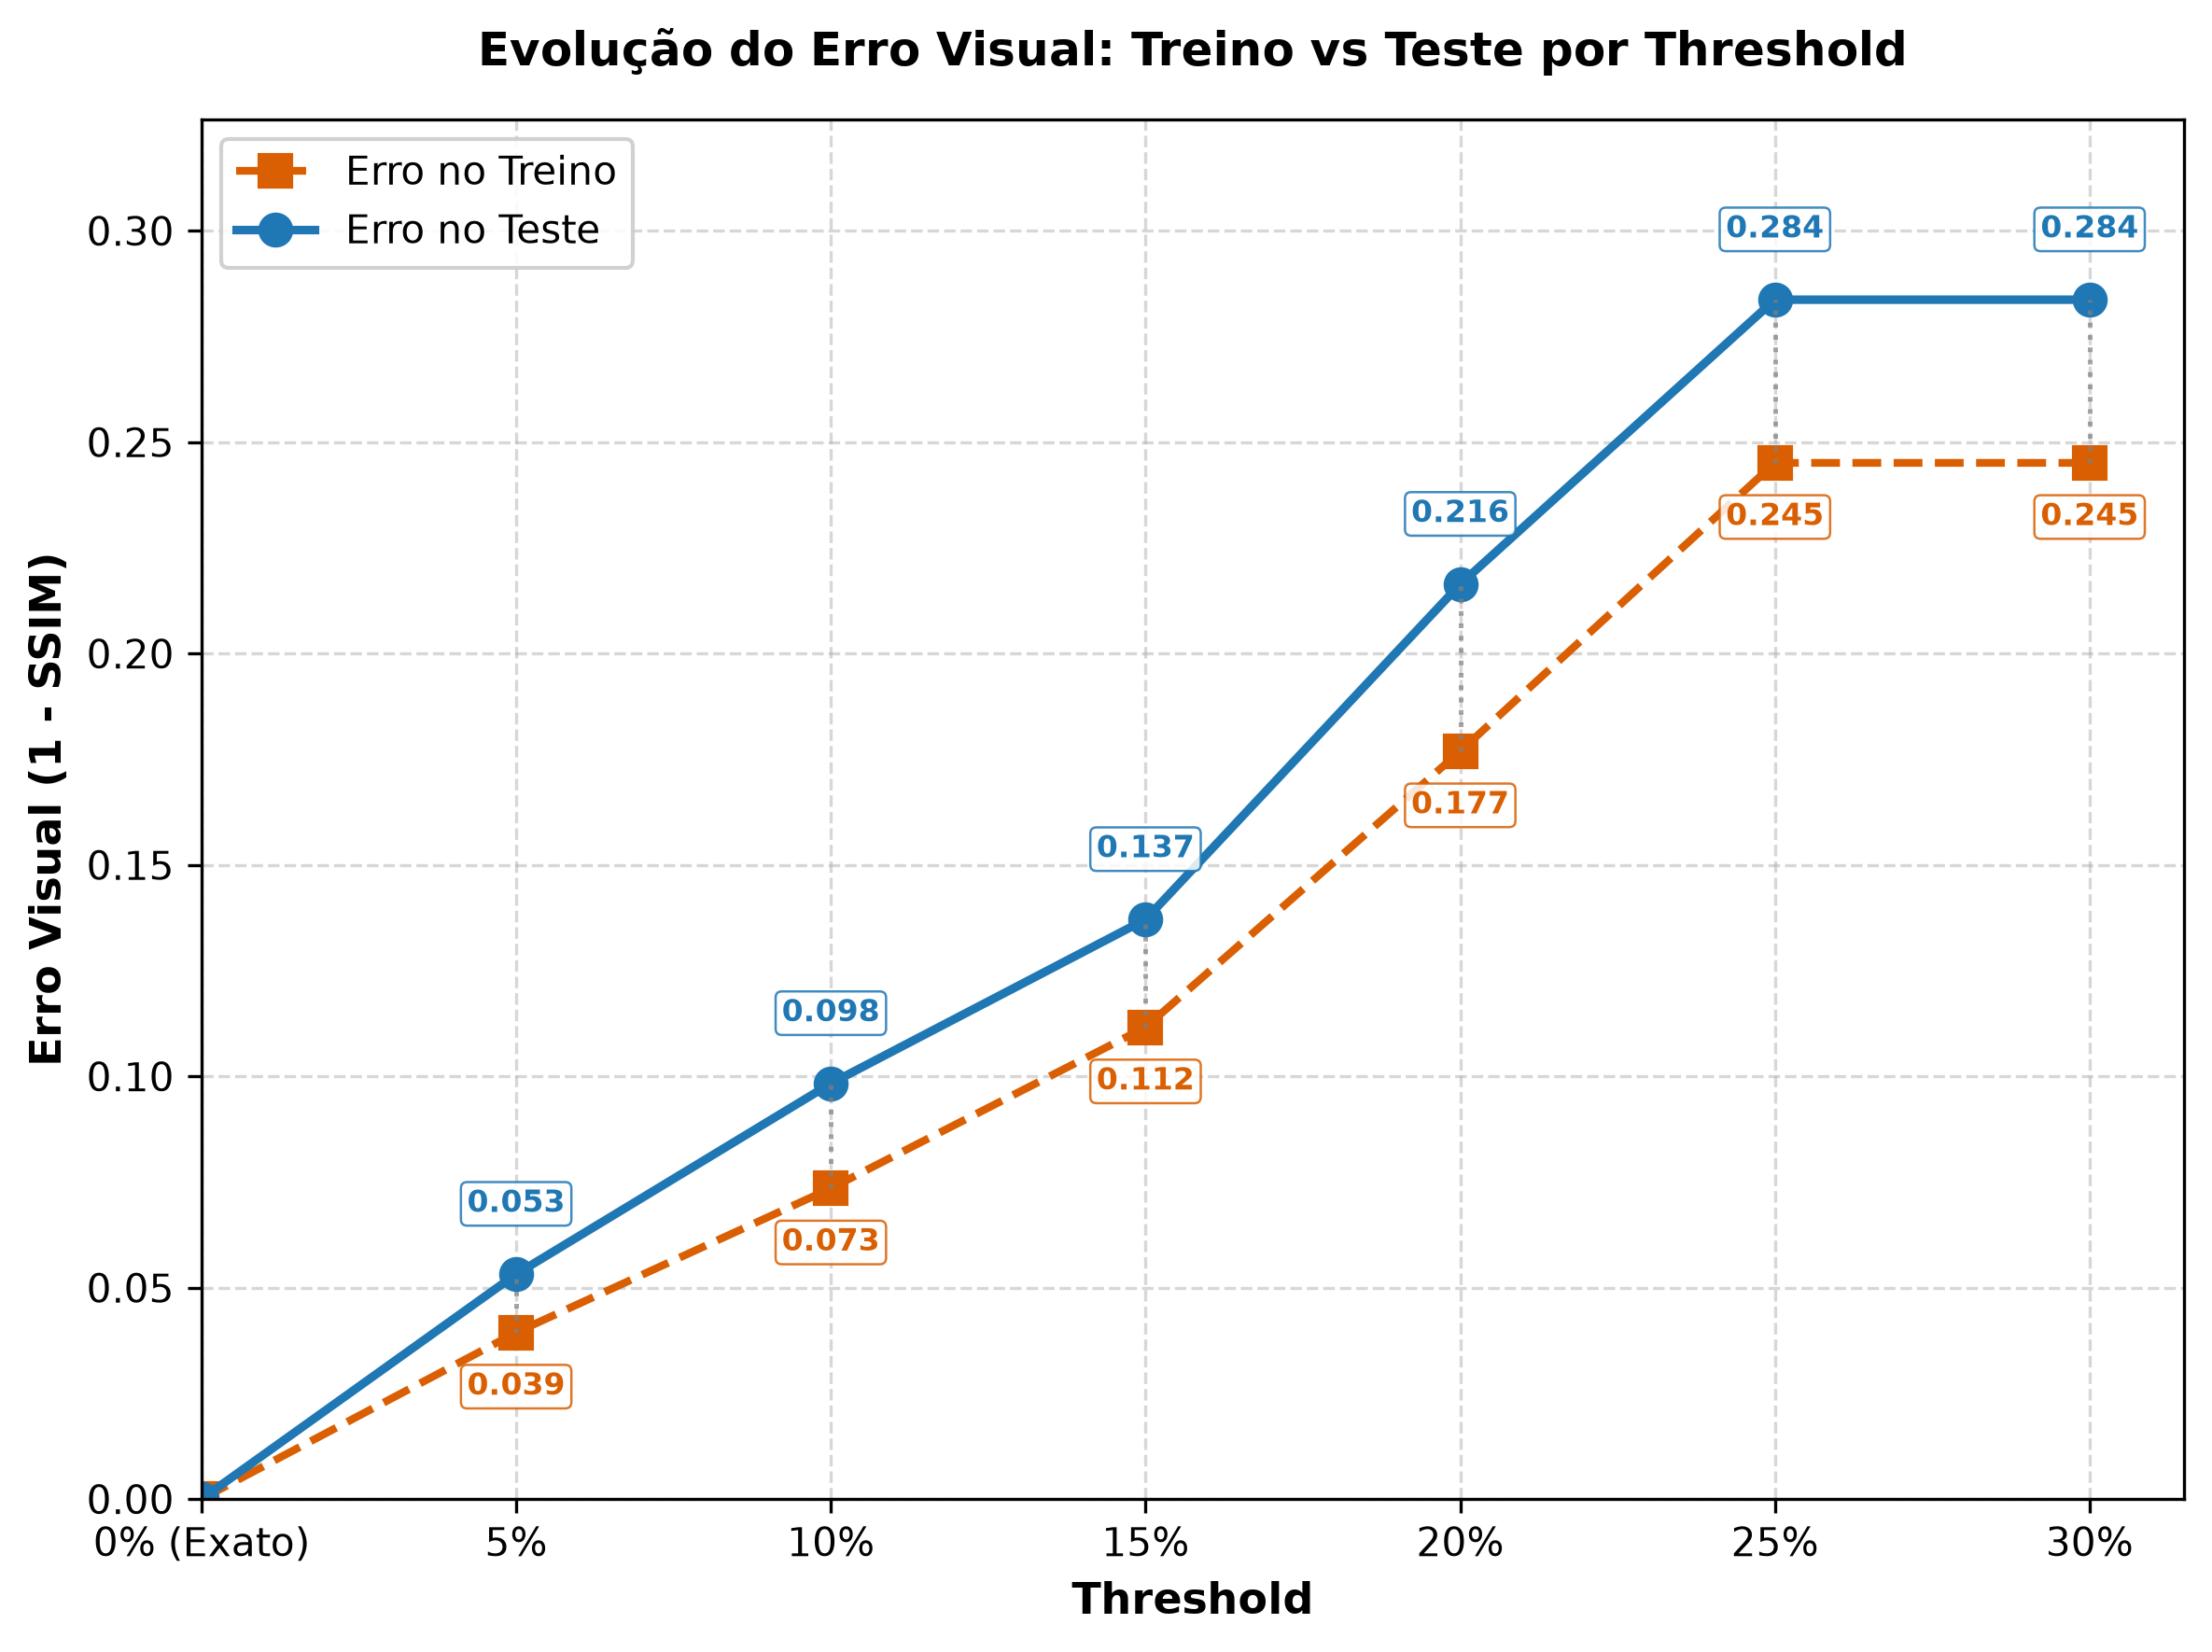

In [30]:
import re
import pandas as pd
import matplotlib.pyplot as plt

# Carrega os resultados do DSE GRASP
df_resultados = pd.read_csv("resultados_dse_grasp.csv")

# Só mostra os números a partir deste threshold (em %)
LIMIAR_ANOTACAO = 5


def threshold_para_numero(valor):
    """Converte rótulos como 'Exato', '5%', '10 %' ou 5 em número (Exato = 0)."""
    s = str(valor).strip().lower()
    achado = re.search(r"\d+(?:[.,]\d+)?", s)
    if achado is None:  # 'Exato' ou qualquer rótulo sem número
        return 0.0
    return float(achado.group().replace(",", "."))


plt.figure(figsize=(8, 6), dpi=300)

# Plota a linha de Treino
plt.plot(
    df_resultados["Threshold"],
    df_resultados["Erro_Treino"],
    marker="s",
    linestyle="--",
    color="#d95f02",
    linewidth=2.0,
    markersize=8,
    label="Erro no Treino"
)

# Plota a linha de Teste
plt.plot(
    df_resultados["Threshold"],
    df_resultados["Erro_Teste"],
    marker="o",
    linestyle="-",
    color="#1f77b4",
    linewidth=2.2,
    markersize=8,
    label="Erro no Teste"
)

# Liga o ponto de Treino ao ponto de Teste correspondente a cada Threshold
for _, row in df_resultados.iterrows():
    th = row["Threshold"]
    err_tr = row["Erro_Treino"]
    err_te = row["Erro_Teste"]

    # Linha vertical conectando Treino e Teste
    plt.plot([th, th], [err_tr, err_te], color="gray", linestyle=":", linewidth=1.2, alpha=0.7)

    # Sem números para o exato (e qualquer threshold abaixo de 5%)
    if threshold_para_numero(th) < LIMIAR_ANOTACAO:
        continue

    treino_acima = err_tr >= err_te

    # Anotação do Erro de Treino
    plt.annotate(
        f"{err_tr:.3f}",
        (th, err_tr),
        textcoords="offset points",
        xytext=(0, 16 if treino_acima else -16),
        ha="center",
        fontsize=8,
        fontweight="bold",
        color="#d95f02",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#d95f02", alpha=0.85, lw=0.6)
    )

    # Anotação do Erro de Teste
    plt.annotate(
        f"{err_te:.3f}",
        (th, err_te),
        textcoords="offset points",
        xytext=(0, -16 if treino_acima else 16),
        ha="center",
        fontsize=8,
        fontweight="bold",
        color="#1f77b4",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#1f77b4", alpha=0.85, lw=0.6)
    )

plt.title(
    "Evolução do Erro Visual: Treino vs Teste por Threshold",
    fontsize=12,
    fontweight="bold",
    pad=14
)

plt.xlabel("Threshold", fontsize=11, fontweight="bold")
plt.ylabel("Erro Visual (1 - SSIM)", fontsize=11, fontweight="bold")
plt.legend(framealpha=0.9, loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)

# Ambos os eixos começam em 0
y_max = max(df_resultados["Erro_Treino"].max(), df_resultados["Erro_Teste"].max())
plt.xlim(left=0)
plt.ylim(bottom=0, top=y_max * 1.15)

plt.tight_layout()

# Salva as imagens em alta resolução
plt.savefig("grafico_comparacao_erro_visual.png", dpi=300, bbox_inches="tight")
plt.savefig("grafico_comparacao_erro_visual.pdf", bbox_inches="tight")
plt.show()

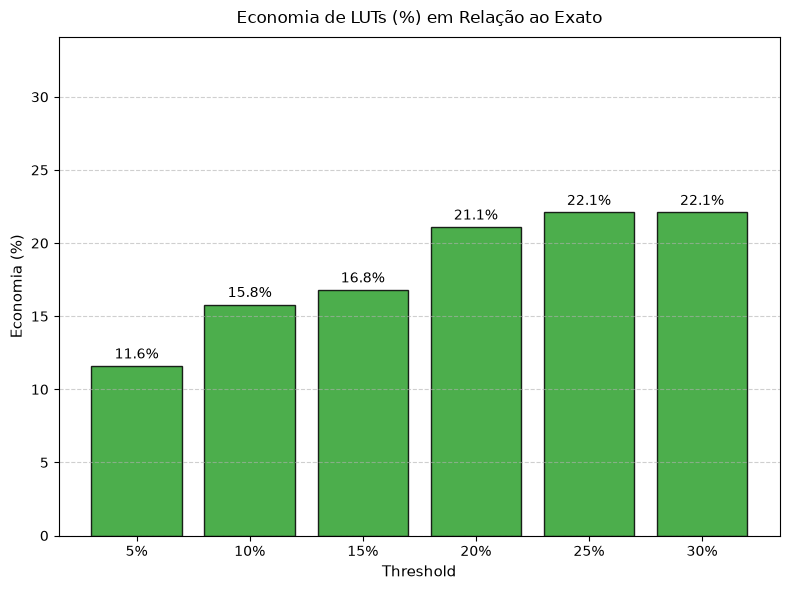

In [7]:
plt.figure(figsize=(8, 6))

df_aprox = df_resultados[df_resultados["Limite_Erro"] > 0]

if not df_aprox.empty:

    bars = plt.bar(
        df_aprox["Threshold"],
        df_aprox["Economia (%)"],
        color="#2ca02c",
        edgecolor="black",
        alpha=0.85
    )

    plt.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3
    )

plt.title(
    "Economia de LUTs (%) em Relação ao Exato",
    fontsize=12,
    pad=10
)

plt.xlabel("Threshold", fontsize=11)
plt.ylabel("Economia (%)", fontsize=11)

if not df_resultados.empty:
    plt.ylim(
        0,
        df_resultados["Economia (%)"].max() + 12
    )

plt.grid(
    True,
    linestyle="--",
    alpha=0.6,
    axis="y"
)

plt.tight_layout()

plt.savefig(
    "grafico_economia_luts_ssimGeometrica.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

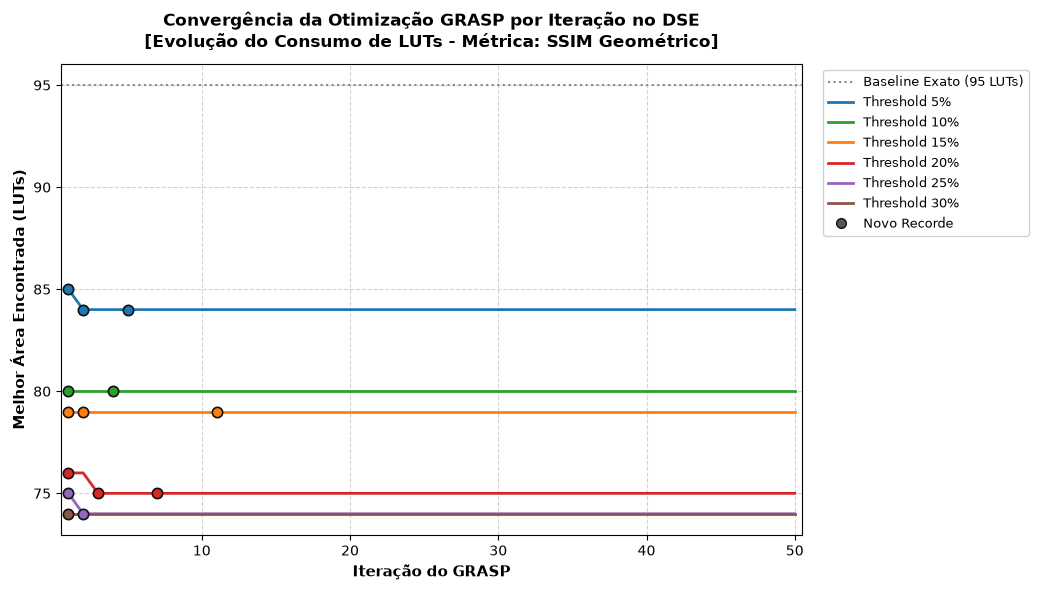

✔ Gráficos de convergência salvos: 'grafico_convergencia_grasp_dse.png' e '.pdf'

--- Validação e Diagnóstico do Algoritmo GRASP ---


,Threshold,Área Final (LUTs),Iteração Vencedora,Total de Recordes,Viabilidade da RCL (%),Redução Acum. Busca Local (LUTs),Tempo Total (s)
0,10%,80,4,2,100.0%,257,3155.4
1,15%,79,11,3,100.0%,157,2248.1
2,20%,75,7,3,100.0%,306,2906.8
3,25%,74,2,2,100.0%,313,2017.5
4,30%,74,1,1,100.0%,278,1972.1
5,5%,84,5,3,100.0%,142,3021.5


In [ ]:
# Gráfico de Convergência do GRASP por Iteração (Validação da Meta-Heurística)
plt.figure(figsize=(8, 6), dpi=300)

cores_th = {
    "5%": "#1f77b4",
    "10%": "#2ca02c",
    "15%": "#ff7f0e",
    "20%": "#d62728",
    "25%": "#9467bd",
    "30%": "#8c564b"
}

plt.axhline(CUSTO_EXATO, color="#7f8c8d", linestyle=":", linewidth=1.5, label=f"Baseline Exato ({CUSTO_EXATO} LUTs)")

for th_tag in df_trace["Threshold"].unique():
    sub = df_trace[df_trace["Threshold"] == th_tag].copy()
    cor = cores_th.get(th_tag, "#333333")
    sub["Melhor_Area_Global"] = sub["Melhor_Area_Global"].ffill()
    plt.plot(
        sub["Iteracao"],
        sub["Melhor_Area_Global"],
        color=cor,
        linewidth=2.0,
        label=f"Threshold {th_tag}"
    )
    recordes = sub[sub["Bateu_Recorde"] == True]
    if not recordes.empty:
        plt.scatter(
            recordes["Iteracao"],
            recordes["Melhor_Area_Global"],
            color=cor,
            edgecolors="#111111",
            s=55,
            linewidth=1.2,
            zorder=4
        )

plt.title("Convergência da Otimização GRASP por Iteração no DSE\n[Evolução do Consumo de LUTs - Métrica: SSIM Geométrico]", fontsize=12, fontweight="bold", pad=12)
plt.xlabel("Iteração do GRASP", fontsize=11, fontweight="bold")
plt.ylabel("Melhor Área Encontrada (LUTs)", fontsize=11, fontweight="bold")
plt.xlim(0.5, MAX_ITERACOES + 0.5)
plt.grid(True, linestyle="--", alpha=0.55)

handles, labels = plt.gca().get_legend_handles_labels()
from matplotlib.lines import Line2D
handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="#555555", markeredgecolor="#111111", markersize=7, label="Novo Recorde"))
plt.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=True, framealpha=0.9, fontsize=9)
plt.tight_layout()

plt.savefig("grafico_convergencia_grasp_dse.png", dpi=300, bbox_inches="tight")
plt.savefig("grafico_convergencia_grasp_dse.pdf", bbox_inches="tight")
plt.show()
print("✔ Gráficos de convergência salvos: 'grafico_convergencia_grasp_dse.png' e '.pdf'")

# Tabela Diagnóstica de Validação do GRASP
diag = []
for th_tag, grp in df_trace.groupby("Threshold"):
    rec_count = int(grp["Bateu_Recorde"].sum())
    viavel_pct = 100.0 * grp["Viavel"].mean()
    ganho_busca_local = int(grp["Melhoria_Area_Local"].sum())
    tempo_total = float(grp["Tempo_Iteracao_s"].sum())
    vencedor = grp[grp["Bateu_Recorde"] == True].iloc[-1] if rec_count > 0 else None
    iter_venc = int(vencedor["Iteracao"]) if vencedor is not None else 0
    area_final = int(vencedor["Melhor_Area_Global"]) if vencedor is not None else 0
    diag.append({
        "Threshold": th_tag,
        "Área Final (LUTs)": area_final,
        "Iteração Vencedora": iter_venc,
        "Total de Recordes": rec_count,
        "Viabilidade da RCL (%)": f"{viavel_pct:.1f}%",
        "Redução Acum. Busca Local (LUTs)": ganho_busca_local,
        "Tempo Total (s)": round(tempo_total, 1)
    })
df_diag = pd.DataFrame(diag)
print()
print("--- Validação e Diagnóstico do Algoritmo GRASP ---")
display(df_diag)

## 6. Inspeção Visual das Imagens de Borda
Comparação lado a lado entre a imagem original do conjunto de teste (ex: `71.ppm`), a saída do filtro Sobel Exato e as saídas aproximadas para cada threshold gerado pelo GRASP.
Em cima de cada imagem são exibidas as métricas de qualidade (Erro, SSIM e PSNR) calculadas com base na imagem exata.


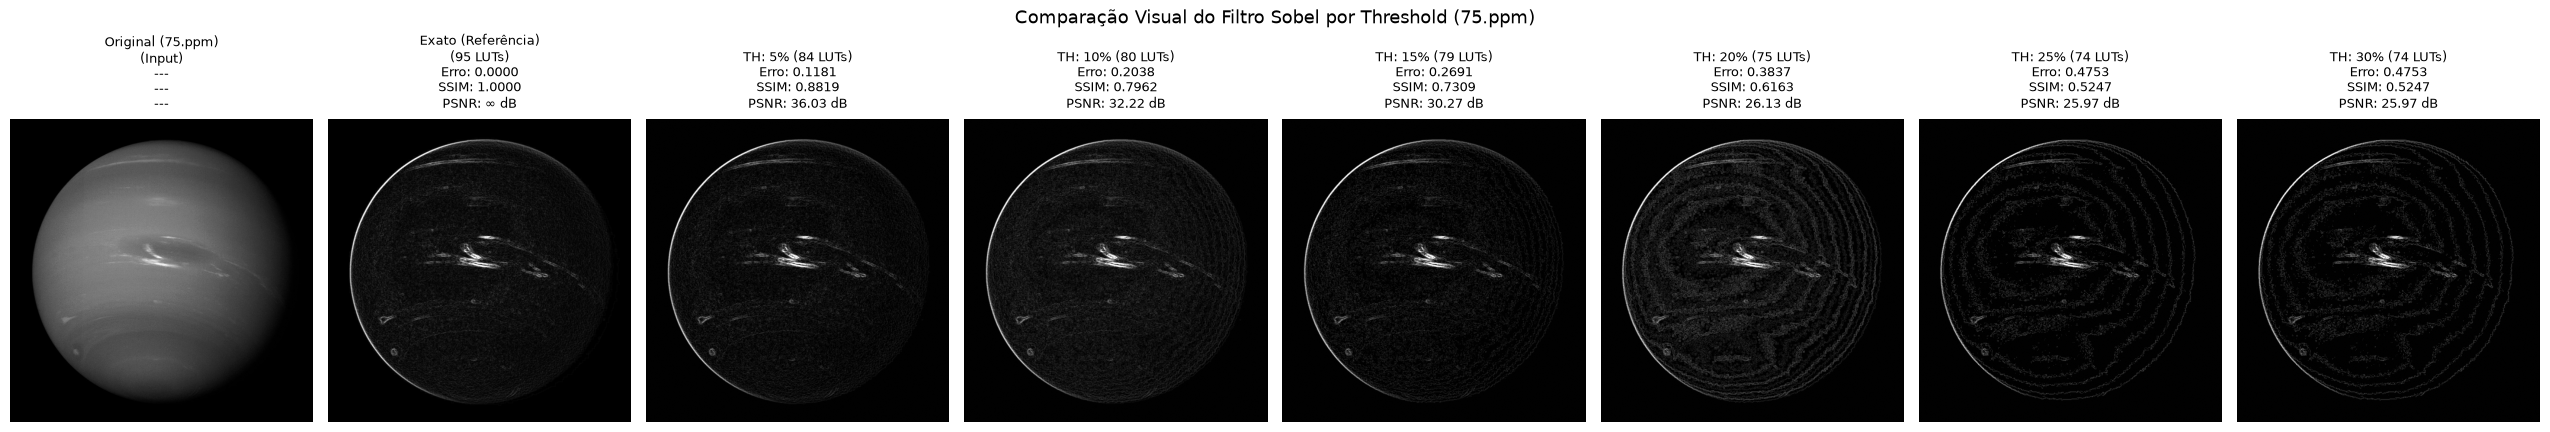

✔ Visualização gerada e salva com sucesso:
  - comparacao_todos_thresholds.png
  - comparacao_todos_thresholds.pdf


In [4]:
# ============================================================
# CONFIGURAÇÃO DA IMAGEM DE TESTE (Autossuficiente)
# ============================================================
# Altere o número abaixo para inspecionar outra imagem da pasta 512x512 (ex: "71", "75", "80", "95")
ID_IMAGEM = "75"
COLUNAS_GRID = 4  # Formato de Grid: 4 colunas x 2 linhas = 8 imagens
DATASET_DIR = "image_dataset-main/512x512"
OUTPUT_DIR = "results" if os.path.isdir("results") else "."

import os
import ast
import math
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim

# 1. Garante que df_resultados esteja carregado mesmo sem rodar o GRASP novamente
if "df_resultados" not in globals() or df_resultados is None or df_resultados.empty:
    csv_candidatos = ["results/resultados_dse_grasp.csv", "resultados_dse_grasp.csv"]
    csv_encontrado = next((p for p in csv_candidatos if os.path.exists(p)), None)
    if csv_encontrado:
        print(f"📂 Carregando resultados salvos de '{csv_encontrado}'...")
        df_resultados = pd.read_csv(csv_encontrado)
    else:
        raise FileNotFoundError(
            "Arquivo 'resultados_dse_grasp.csv' não encontrado! Execute o DSE ao menos uma vez."
        )

img_orig_path = os.path.join(DATASET_DIR, f"{ID_IMAGEM}.ppm")

# Busca flexível pela imagem exata de referência
candidatos_exata = [
    os.path.join(DATASET_DIR, f"{ID_IMAGEM}_precise.ppm"),
    os.path.join(DATASET_DIR, f"{ID_IMAGEM}.precise.sobel.ppm"),
]
img_exata_path = next((p for p in candidatos_exata if os.path.exists(p)), candidatos_exata[0])

# Se a imagem exata não existir ainda, gera automaticamente
if not os.path.exists(img_exata_path) and os.path.exists(img_orig_path):
    try:
        from grasp.avaliador import compilar_referencia_exata
        import subprocess
        bin_exato = compilar_referencia_exata()
        subprocess.run([bin_exato, img_orig_path, img_exata_path], check=True)
    except Exception as e:
        print(f"⚠️ Não foi possível gerar a imagem exata automaticamente: {e}")

if os.path.exists(img_orig_path) and os.path.exists(img_exata_path):
    img_orig = cv2.imread(img_orig_path, cv2.IMREAD_GRAYSCALE)
    img_exata = cv2.imread(img_exata_path, cv2.IMREAD_GRAYSCALE)

    # Filtra apenas as linhas que possuem designs aproximados válidos
    df_aprox = df_resultados[df_resultados["Limite_Erro"] > 0].reset_index(drop=True)

    total_imagens = len(df_aprox) + 2  # Original + Exato + (N thresholds)
    ncols = min(max(1, int(COLUNAS_GRID)), total_imagens)
    nrows = math.ceil(total_imagens / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(2.75 * ncols, 3.55 * nrows),
        sharex=True,
        sharey=True
    )
    axes_flat = np.array(axes).reshape(-1)

    def estilizar_eixo(ax, titulo_topo, texto_baixo=""):
        ax.set_title(titulo_topo, fontsize=13, fontweight="normal", pad=6)
        ax.tick_params(axis="both", which="major", labelsize=10)
        if texto_baixo:
            ax.set_xlabel(texto_baixo, fontsize=11.5, fontweight="normal", labelpad=6)

    # 1. Imagem Original
    axes_flat[0].imshow(img_orig, cmap="gray")
    estilizar_eixo(axes_flat[0], "Original")

    # 2. Sobel Exato
    axes_flat[1].imshow(img_exata, cmap="gray")
    estilizar_eixo(axes_flat[1], "Exato")

    # 3. Sobel Aproximado para cada Threshold
    for idx, row in df_aprox.iterrows():
        th_val = float(row["Limite_Erro"])
        th_tag = int(round(th_val * 100))

        candidatos_aprox = [
            os.path.join(DATASET_DIR, f"{ID_IMAGEM}_approx_th{th_tag}.ppm"),
            os.path.join(DATASET_DIR, f"{ID_IMAGEM}_th{th_tag}.sobel.ppm"),
            os.path.join(DATASET_DIR, f"{ID_IMAGEM}.approx.sobel.ppm") if idx == len(df_aprox) - 1 else ""
        ]
        img_aprox_path = next((p for p in candidatos_aprox if p and os.path.exists(p)), None)

        # Se a imagem daquele threshold para este ID não existir no disco, gera sob demanda!
        if img_aprox_path is None and "Configuracao" in row:
            try:
                from grasp.gerador_codigo import gerar_sobel_cpp
                import subprocess
                cfg = ast.literal_eval(row["Configuracao"]) if isinstance(row["Configuracao"], str) else row["Configuracao"]
                cpp_temp = f"sobel_inspect_th{th_tag}.cpp"
                bin_temp = f"./sobel_inspect_th{th_tag}.out"
                gerar_sobel_cpp(cfg, cpp_temp)
                subprocess.run(["g++", "-O3", cpp_temp, "-o", bin_temp], check=True)
                img_aprox_path = os.path.join(DATASET_DIR, f"{ID_IMAGEM}_approx_th{th_tag}.ppm")
                subprocess.run([bin_temp, img_orig_path, img_aprox_path], check=True)
                for tmp in (cpp_temp, bin_temp):
                    if os.path.exists(tmp):
                        os.remove(tmp)
            except Exception as e:
                print(f"⚠️ Erro ao gerar imagem sob demanda para TH {th_tag}%: {e}")

        ax = axes_flat[idx + 2]
        if img_aprox_path and os.path.exists(img_aprox_path):
            img_aprox = cv2.imread(img_aprox_path, cv2.IMREAD_GRAYSCALE)
            ax.imshow(img_aprox, cmap="gray")

            # Métricas individuais desta imagem específica em relação à exata
            val_ssim = ssim(img_exata, img_aprox, data_range=255)
            diff_sq = (img_exata.astype(np.float64) - img_aprox.astype(np.float64)) ** 2
            val_mse = np.mean(diff_sq)
            val_psnr = cv2.PSNR(img_exata, img_aprox) if val_mse > 0 else float("inf")

            estilizar_eixo(
                ax,
                f"Threshold: {th_tag}%",
                f"SSIM: {val_ssim:.4f}\nPSNR: {val_psnr:.2f}"
            )
        else:
            ax.text(0.5, 0.5, "Imagem não encontrada", horizontalalignment="center", verticalalignment="center", fontsize=11)
            estilizar_eixo(
                ax,
                f"Threshold: {th_tag}%",
                "SSIM: N/A\nPSNR: N/A"
            )

    for extra_idx in range(total_imagens, len(axes_flat)):
        axes_flat[extra_idx].axis("off")

    plt.tight_layout(h_pad=2.4, w_pad=0.8)

    os.makedirs(OUTPUT_DIR, exist_ok=True)
    out_png = os.path.join(OUTPUT_DIR, f"comparacao_todos_thresholds_{ID_IMAGEM}.png")
    out_pdf = os.path.join(OUTPUT_DIR, f"comparacao_todos_thresholds_{ID_IMAGEM}.pdf")
    plt.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.savefig(out_pdf, bbox_inches="tight")
    plt.savefig(os.path.join(OUTPUT_DIR, "comparacao_todos_thresholds.png"), dpi=300, bbox_inches="tight")
    plt.savefig(os.path.join(OUTPUT_DIR, "comparacao_todos_thresholds.pdf"), bbox_inches="tight")
    plt.show()
    print(f"✔ Painel comparativo (Grid {nrows}x{ncols}) salvo em '{out_png}' e '{out_pdf}'.")
else:
    print(f"⚠️ Imagem {ID_IMAGEM}.ppm não encontrada em '{DATASET_DIR}'. Verifique se o ID existe.")


## 7. Geração de Hardware (C++ HLS) e Automação de Síntese no Vitis



In [15]:
import os
import stat
import textwrap
import pandas as pd

# ==============================================================================
# CONFIGURAÇÃO: MÉTRICA PARA GERAÇÃO DO HARDWARE C++ E SCRIPTS DE SÍNTESE
# ==============================================================================
# Escolha para qual métrica deseja gerar os arquivos C++ e scripts de síntese:
# Opções disponíveis: "mediana", "geometrico", "media"
METRICA_GERAR = "geometrico"

MAPA_GERACAO = {
    "mediana": {
        "src": "src_sintese_mediana",
        "reports": "reports_sintese_mediana",
        "tcl": "sintese_sobel_mediana.tcl",
        "sh": "executar_sintese_vitis_mediana.sh",
        "csv": "resultados_dse_grasp_ssimMediana.csv"
    },
    "geometrico": {
        "src": "src_sintese_geometrico",
        "reports": "reports_sintese_geometrico",
        "tcl": "sintese_sobel_geometrico.tcl",
        "sh": "executar_sintese_vitis_geometrico.sh",
        "csv": "resultados_dse_grasp_ssimGeometrica.csv" if os.path.exists("resultados_dse_grasp_ssimGeometrica.csv") else "resultados_dse_grasp_ssimGeometrico.csv"
    },
    "geometrica": {
        "src": "src_sintese_geometrico",
        "reports": "reports_sintese_geometrico",
        "tcl": "sintese_sobel_geometrico.tcl",
        "sh": "executar_sintese_vitis_geometrico.sh",
        "csv": "resultados_dse_grasp_ssimGeometrica.csv" if os.path.exists("resultados_dse_grasp_ssimGeometrica.csv") else "resultados_dse_grasp_ssimGeometrico.csv"
    },
    "media": {
        "src": "src_sintese_media",
        "reports": "reports_sintese_media",
        "tcl": "sintese_sobel_media.tcl",
        "sh": "executar_sintese_vitis_ssimmedio.sh",
        "csv": "resultados_dse_grasp_ssimMedia.csv"
    }
}

chave_gerar = METRICA_GERAR.strip().lower()
cfg_gerar = MAPA_GERACAO.get(chave_gerar, MAPA_GERACAO["mediana"])

PASTA_SRC_SINTESE = cfg_gerar["src"]
PASTA_REPORTS     = cfg_gerar["reports"]
ARQUIVO_TCL       = cfg_gerar["tcl"]
ARQUIVO_SH        = cfg_gerar["sh"]
ARQUIVO_CSV_DSE   = cfg_gerar["csv"]
TEMPLATE_CPP      = "template_sobel.cpp"

os.makedirs(PASTA_SRC_SINTESE, exist_ok=True)
os.makedirs(PASTA_REPORTS, exist_ok=True)

# Mapeamento oficial dos 11 somadores da biblioteca para os cabeçalhos em templates/
NOMES_SOMADORES_CPP = [
    "add_exact",
    "add_trunc0_1", "add_trunc0_2", "add_trunc0_3", "add_trunc0_4", "add_trunc0_5",
    "add_trunc1_1", "add_trunc1_2", "add_trunc1_3", "add_trunc1_4", "add_trunc1_5"
]

# 1. Carrega o template base do Sobel em C++
with open(TEMPLATE_CPP, "r", encoding="utf-8") as f:
    template_codigo = f.read()

# 2. Carrega resultados do DSE correspondente
if os.path.exists(ARQUIVO_CSV_DSE):
    df_resultados_gerar = pd.read_csv(ARQUIVO_CSV_DSE)
    print(f"✔ Carregando resultados DSE de '{ARQUIVO_CSV_DSE}'")
elif "df_resultados" in globals() and df_resultados is not None:
    df_resultados_gerar = df_resultados
    print("✔ Utilizando 'df_resultados' presente na memória do notebook.")
else:
    raise FileNotFoundError(f"Arquivo '{ARQUIVO_CSV_DSE}' não encontrado para gerar o hardware.")

pontos_sintese = []

print("=" * 75)
print(f" GERANDO HARDWARE C++ (HLS) E SCRIPTS DE SÍNTESE VITIS [{chave_gerar.upper()}]")
print("=" * 75)

for idx, row in df_resultados_gerar.iterrows():
    setup = row['Setup']
    if isinstance(setup, str):
        import ast
        setup = ast.literal_eval(setup)
    
    th_val = float(row['Limite_Erro'])
    th_pct = int(round(th_val * 100))
    tag = f"th_{th_pct:02d}"
    desc = "Baseline (Tudo Exato)" if th_pct == 0 else f"Threshold {th_pct}%"
    arquivo_cpp = f"{PASTA_SRC_SINTESE}/sobel_{tag}.cpp"
    proj_name = f"proj_sobel_{tag}"
    
    # Substitui 'add1' a 'add4' no template C++
    codigo_gerado = template_codigo
    funcoes_cpp = []
    for i, somador_idx in enumerate(setup):
        marcador = f'"add{i+1}"'
        funcao_cpp = NOMES_SOMADORES_CPP[somador_idx]
        codigo_gerado = codigo_gerado.replace(marcador, funcao_cpp)
        funcoes_cpp.append(funcao_cpp)
        
    with open(arquivo_cpp, "w", encoding="utf-8") as f:
        f.write(codigo_gerado)
        
    pontos_sintese.append({
        "tag": tag,
        "th_pct": th_pct,
        "th_val": th_val,
        "desc": desc,
        "setup": setup,
        "funcoes": funcoes_cpp,
        "arquivo_cpp": arquivo_cpp,
        "proj_name": proj_name,
        "luts_estimadas": row['LUTs'],
        "ssim": row.get('SSIM_Teste', 'N/A')
    })
    
    print(f"  ✓ [{tag}] {desc:<22} -> {arquivo_cpp} | Setup: {setup} ({funcoes_cpp})")

# 3. Gera o script TCL para o Vitis HLS (Spartan-7 xc7s50csga324-1 @ 100MHz)
with open(ARQUIVO_TCL, "w", encoding="utf-8") as f:
    f.write("# ==============================================================================\n")
    f.write("# sintese_sobel.tcl - Automação da Síntese Vitis HLS para o Filtro Sobel\n")
    f.write("# Dispositivo: Xilinx Spartan-7 (xc7s50csga324-1) | Clock: 10 ns (100 MHz)\n")
    f.write("# ==============================================================================\n\n")
    f.write('set PART "xc7s50csga324-1"\n')
    f.write('set CLK_PERIOD 10\n')
    f.write(f'set REPORTS_DIR "{PASTA_REPORTS}"\n')
    f.write('file mkdir $REPORTS_DIR\n\n')
    
    f.write("set configs {\n")
    for p in pontos_sintese:
        f.write(f'    {{"{p["tag"]}" "{p["arquivo_cpp"]}" "{p["proj_name"]}" "{p["desc"]}"}}\n')
    f.write("}\n\n")
    
    f.write("foreach cfg $configs {\n")
    f.write("    set tag   [lindex $cfg 0]\n")
    f.write("    set src   [lindex $cfg 1]\n")
    f.write("    set proj  [lindex $cfg 2]\n")
    f.write("    set desc  [lindex $cfg 3]\n\n")
    f.write('    puts "\\n=================================================================="\n')
    f.write('    puts " === VITIS HLS: SINTETIZANDO $desc ($tag) ==="\n')
    f.write('    puts " Arquivo: $src | Projeto: $proj"\n')
    f.write('    puts "=================================================================="\n\n')
    f.write("    open_project $proj -reset\n")
    f.write('    add_files $src -cflags "-I. -Itemplates"\n')
    f.write("    set_top sobel\n\n")
    f.write('    open_solution "solution1" -reset\n')
    f.write("    set_part $PART\n")
    f.write("    create_clock -period $CLK_PERIOD -name default\n\n")
    f.write('    puts "--- Executando C-Synthesis (csynth_design) ---\n"')
    f.write("    csynth_design\n\n")
    f.write('    set rpt_file "$proj/solution1/syn/report/sobel_csynth.rpt"\n')
    f.write('    set xml_file "$proj/solution1/syn/report/sobel_csynth.xml"\n')
    f.write('    if {[file exists $rpt_file]} {\n')
    f.write('        file copy -force $rpt_file "$REPORTS_DIR/${tag}_csynth.rpt"\n')
    f.write('        puts "✔ Relatório salvo em: $REPORTS_DIR/${tag}_csynth.rpt"\n')
    f.write('    }\n')
    f.write('    if {[file exists $xml_file]} {\n')
    f.write('        file copy -force $xml_file "$REPORTS_DIR/${tag}_csynth.xml"\n')
    f.write('        puts "✔ Relatório XML salvo em: $REPORTS_DIR/${tag}_csynth.xml"\n')
    f.write('    }\n\n')
    f.write("    close_project\n")
    f.write("}\n\n")
    f.write('puts "\\n=================================================================="\n')
    f.write('puts "✔ SÍNTESE CONCLUÍDA PARA TODOS OS DESIGNS (BASELINE + 5% A 30%)!"\n')
    f.write('puts "==================================================================\\n"\n')
    f.write("exit\n")

# 4. Gera o script Shell (.sh) para disparar o Vitis HLS
sh_lines = [
    "#!/usr/bin/env bash",
    "# ==============================================================================",
    f"# {ARQUIVO_SH}",
    f"# Script para chamar o Vitis HLS e sintetizar o Full Design ({chave_gerar.upper()})",
    "# Baseline (Tudo Exato) e Aproximações GRASP (5% a 30%)",
    "# ==============================================================================",
    "",
    "set -e",
    "",
    "echo '=================================================================='",
    f"echo '    SÍNTESE VITIS HLS: SOBEL FULL DESIGN [{chave_gerar.upper()}]    '",
    "echo '=================================================================='",
    'echo "Data/Hora: $(date)"',  
    'echo "Diretório: $(pwd)"',  
    "echo '------------------------------------------------------------------'",
    "",
    "# 1. Configuração do ambiente Xilinx Vitis",
    "if command -v vitis_hls >/dev/null 2>&1; then",
    '    echo "✔ vitis_hls encontrado no PATH ($(which vitis_hls))."', 
    "else",
    '    SETTINGS_FOUND=""',
    "    POSSIBLE_PATHS=(",
    "        '/tools/Xilinx/Vitis_HLS/2022.2/settings64.sh'",
    "        '/tools/Xilinx/Vitis/2022.2/settings64.sh'",
    "        '/tools/Xilinx/Vivado/2022.2/settings64.sh'",
    "        '/tools/Xilinx/Vitis_HLS/2022.1/settings64.sh'",
    "        '/tools/Xilinx/Vitis/2022.1/settings64.sh'",
    "        '/tools/Xilinx/Vivado/2022.1/settings64.sh'",
    "        '/opt/Xilinx/Vitis_HLS/2022.2/settings64.sh'",
    "        '/opt/Xilinx/Vitis/2022.2/settings64.sh'",
    "        '/opt/Xilinx/Vivado/2022.2/settings64.sh'",
    "    )",
    '    for p in "${POSSIBLE_PATHS[@]}"; do',
    '        if [ -f "$p" ]; then',
    '            SETTINGS_FOUND="$p"',
    "            break",
    "        fi",
    "    done",
    "",
    '    if [ -n "$SETTINGS_FOUND" ]; then',
    '        echo "✔ Carregando variáveis do ambiente Xilinx: $SETTINGS_FOUND"',
    '        source "$SETTINGS_FOUND"',
    "    else",
    '        echo "❌ ERRO: \'vitis_hls\' não encontrado no PATH nem nos diretórios padrão."',
    '        echo "   Execute \'source /caminho/para/settings64.sh\' ou rode no servidor com Vitis instalado."',
    "        exit 1",
    "    fi",
    "fi",
    "",
    "# 2. Executa a síntese em lote via TCL",
    f"TCL_SCRIPT='{ARQUIVO_TCL}'",
    'if [ ! -f "$TCL_SCRIPT" ]; then',
    '    echo "❌ ERRO: Script TCL \'$TCL_SCRIPT\' não encontrado!"',
    "    exit 1",
    "fi",
    "",
    "echo ''",
    "echo '>>> Iniciando síntese em lote no Vitis HLS...'",
    'vitis_hls -f "$TCL_SCRIPT"',
    "",
    "echo ''",
    "echo '=================================================================='",
    f'echo "✔ Síntese finalizada com sucesso! Relatórios salvos em \'{PASTA_REPORTS}/\'"',
    "echo '=================================================================='",
]

with open(ARQUIVO_SH, "w", encoding="utf-8") as f:
    f.write("\n".join(sh_lines) + "\n")

# Atribui permissão de execução (+x)
st = os.stat(ARQUIVO_SH)
os.chmod(ARQUIVO_SH, st.st_mode | stat.S_IEXEC | stat.S_IXGRP | stat.S_IXOTH)

print("\n" + "=" * 75)
print(f"✔ Script Shell gerado: {ARQUIVO_SH}")
print(f"✔ Script TCL gerado:   {ARQUIVO_TCL}")
print(f"✔ Fontes C++ gerados:  {PASTA_SRC_SINTESE}/ ({len(pontos_sintese)} arquivos)")
print("=" * 75)
print("Para sintetizar todo o esquema no Vitis HLS, execute:")
print(f"  bash {ARQUIVO_SH}")


✔ Utilizando 'df_resultados' presente na memória do notebook.
 GERANDO HARDWARE C++ (HLS) E SCRIPTS DE SÍNTESE VITIS [GEOMETRICO]
  ✓ [th_00] Baseline (Tudo Exato)  -> src_sintese_geometrico/sobel_th_00.cpp | Setup: [0, 0, 0, 0, 0] (['add_exact', 'add_exact', 'add_exact', 'add_exact', 'add_exact'])
  ✓ [th_05] Threshold 5%           -> src_sintese_geometrico/sobel_th_05.cpp | Setup: [7, 2, 2, 2, 8] (['add_trunc1_2', 'add_trunc0_2', 'add_trunc0_2', 'add_trunc0_2', 'add_trunc1_3'])
  ✓ [th_10] Threshold 10%          -> src_sintese_geometrico/sobel_th_10.cpp | Setup: [8, 3, 8, 3, 8] (['add_trunc1_3', 'add_trunc0_3', 'add_trunc1_3', 'add_trunc0_3', 'add_trunc1_3'])
  ✓ [th_15] Threshold 15%          -> src_sintese_geometrico/sobel_th_15.cpp | Setup: [8, 8, 8, 8, 9] (['add_trunc1_3', 'add_trunc1_3', 'add_trunc1_3', 'add_trunc1_3', 'add_trunc1_4'])
  ✓ [th_20] Threshold 20%          -> src_sintese_geometrico/sobel_th_20.cpp | Setup: [9, 9, 4, 9, 9] (['add_trunc1_4', 'add_trunc1_4', 'add_trun

## 8. Comparação do Full Design na Placa (Hardware Real vs Estimativa)

Esta seção realiza a validação física e a consolidação dos relatórios gerados pelo **Xilinx Vitis HLS** para a FPGA **Spartan-7 (`xc7s50csga324-1`)**.

### Funcionalidades desta Etapa:
- **Seleção Dinâmica da Métrica**: Alterne facilmente entre `METRICA_ANALISE = "mediana"`, `"geometrico"` ou `"media"` (ou defina diretamente `PASTA_REPORTS_CUSTOM` / `ARQUIVO_CSV_CUSTOM`), permitindo analisar qualquer experimento a qualquer momento sem perder nem sobrescrever os dados anteriores.
- **Extração Tolerante e Precisa**: Extrai automaticamente o consumo de recursos físicos (**LUTs**, **Flip-Flops**, **DSPs**, **BRAMs**) tanto do **Full Design (Top Sobel)** quanto do **Kernel Filtro Sobel (Filter2D)**, além de métricas temporais (**Clock Estimado**, **Frequência Máxima $F_{max}$** e **Slack**).
- **Isolamento de Arquivos**: Salva o CSV consolidado com o identificador da métrica (`resultados_comparacao_full_design_<metrica>.csv`), preservando o histórico de cada bateria de síntese.
- **3 Gráficos Separados e Centralizados**:
  1. **Gráfico 1**: Consumo Físico de LUTs no Full Design (Spartan-7) por Threshold com referência de baseline.
  2. **Gráfico 2**: Comparação de Economia de Hardware: Estimativa do DSE (Somadores) vs. Impacto Real na Placa (%).
  3. **Gráfico 3**: Desempenho Temporal e Frequência Máxima ($F_{max}$ em MHz) vs. Restrição Alvo de 100 MHz.


 VALIDAÇÃO FULL DESIGN VITIS HLS | MÉTRICA: SSIM - GEOMÉTRICA
📁 Pasta de Relatórios HLS : 'reports_sintese_geometrico'
📄 Arquivo DSE de Entrada  : 'resultados_dse_grasp_ssimGeometrico.csv'
✔ Utilizando 'df_resultados' presente na memória do notebook.

✔ Relatórios sintetizados encontrados: 7 de 7


,Threshold,Limite_Erro,SSIM_Teste,LUTs_Est_DSE,Econ_Est_%,LUTs_Full_Design,FFs_Full_Design,DSPs_Full_Design,BRAMs_Full_Design,LUTs_Kernel_Sobel,Clock_Est_ns,Fmax_MHz,Slack_ns,Latencia_Ciclos,Econ_Real_%,Econ_Kernel_%
0,0% (Exato),0.00,1.0000,95,0.0,3013,2680,7,2,1160,7.3,136.99,2.7,Streaming (Dataflow),0.00,0.00
1,5%,0.05,0.9468,84,11.6,2988,2674,7,2,1135,7.3,136.99,2.7,Streaming (Dataflow),0.83,2.16
2,10%,0.10,0.9017,80,15.8,2986,2680,7,2,1133,7.3,136.99,2.7,Streaming (Dataflow),0.90,2.33
3,15%,0.15,0.8629,79,16.8,2985,2680,7,2,1132,7.3,136.99,2.7,Streaming (Dataflow),0.93,2.41
4,20%,0.20,0.7836,75,21.1,2973,2674,7,2,1120,7.3,136.99,2.7,Streaming (Dataflow),1.33,3.45
5,25%,0.25,0.7163,74,22.1,2972,2674,7,2,1119,7.3,136.99,2.7,Streaming (Dataflow),1.36,3.53
6,30%,0.30,0.7163,74,22.1,2972,2674,7,2,1119,7.3,136.99,2.7,Streaming (Dataflow),1.36,3.53


✔ Tabela consolidada salva com sucesso em 'resultados_comparacao_full_design_geometrica.csv' (e 'resultados_comparacao_full_design.csv')


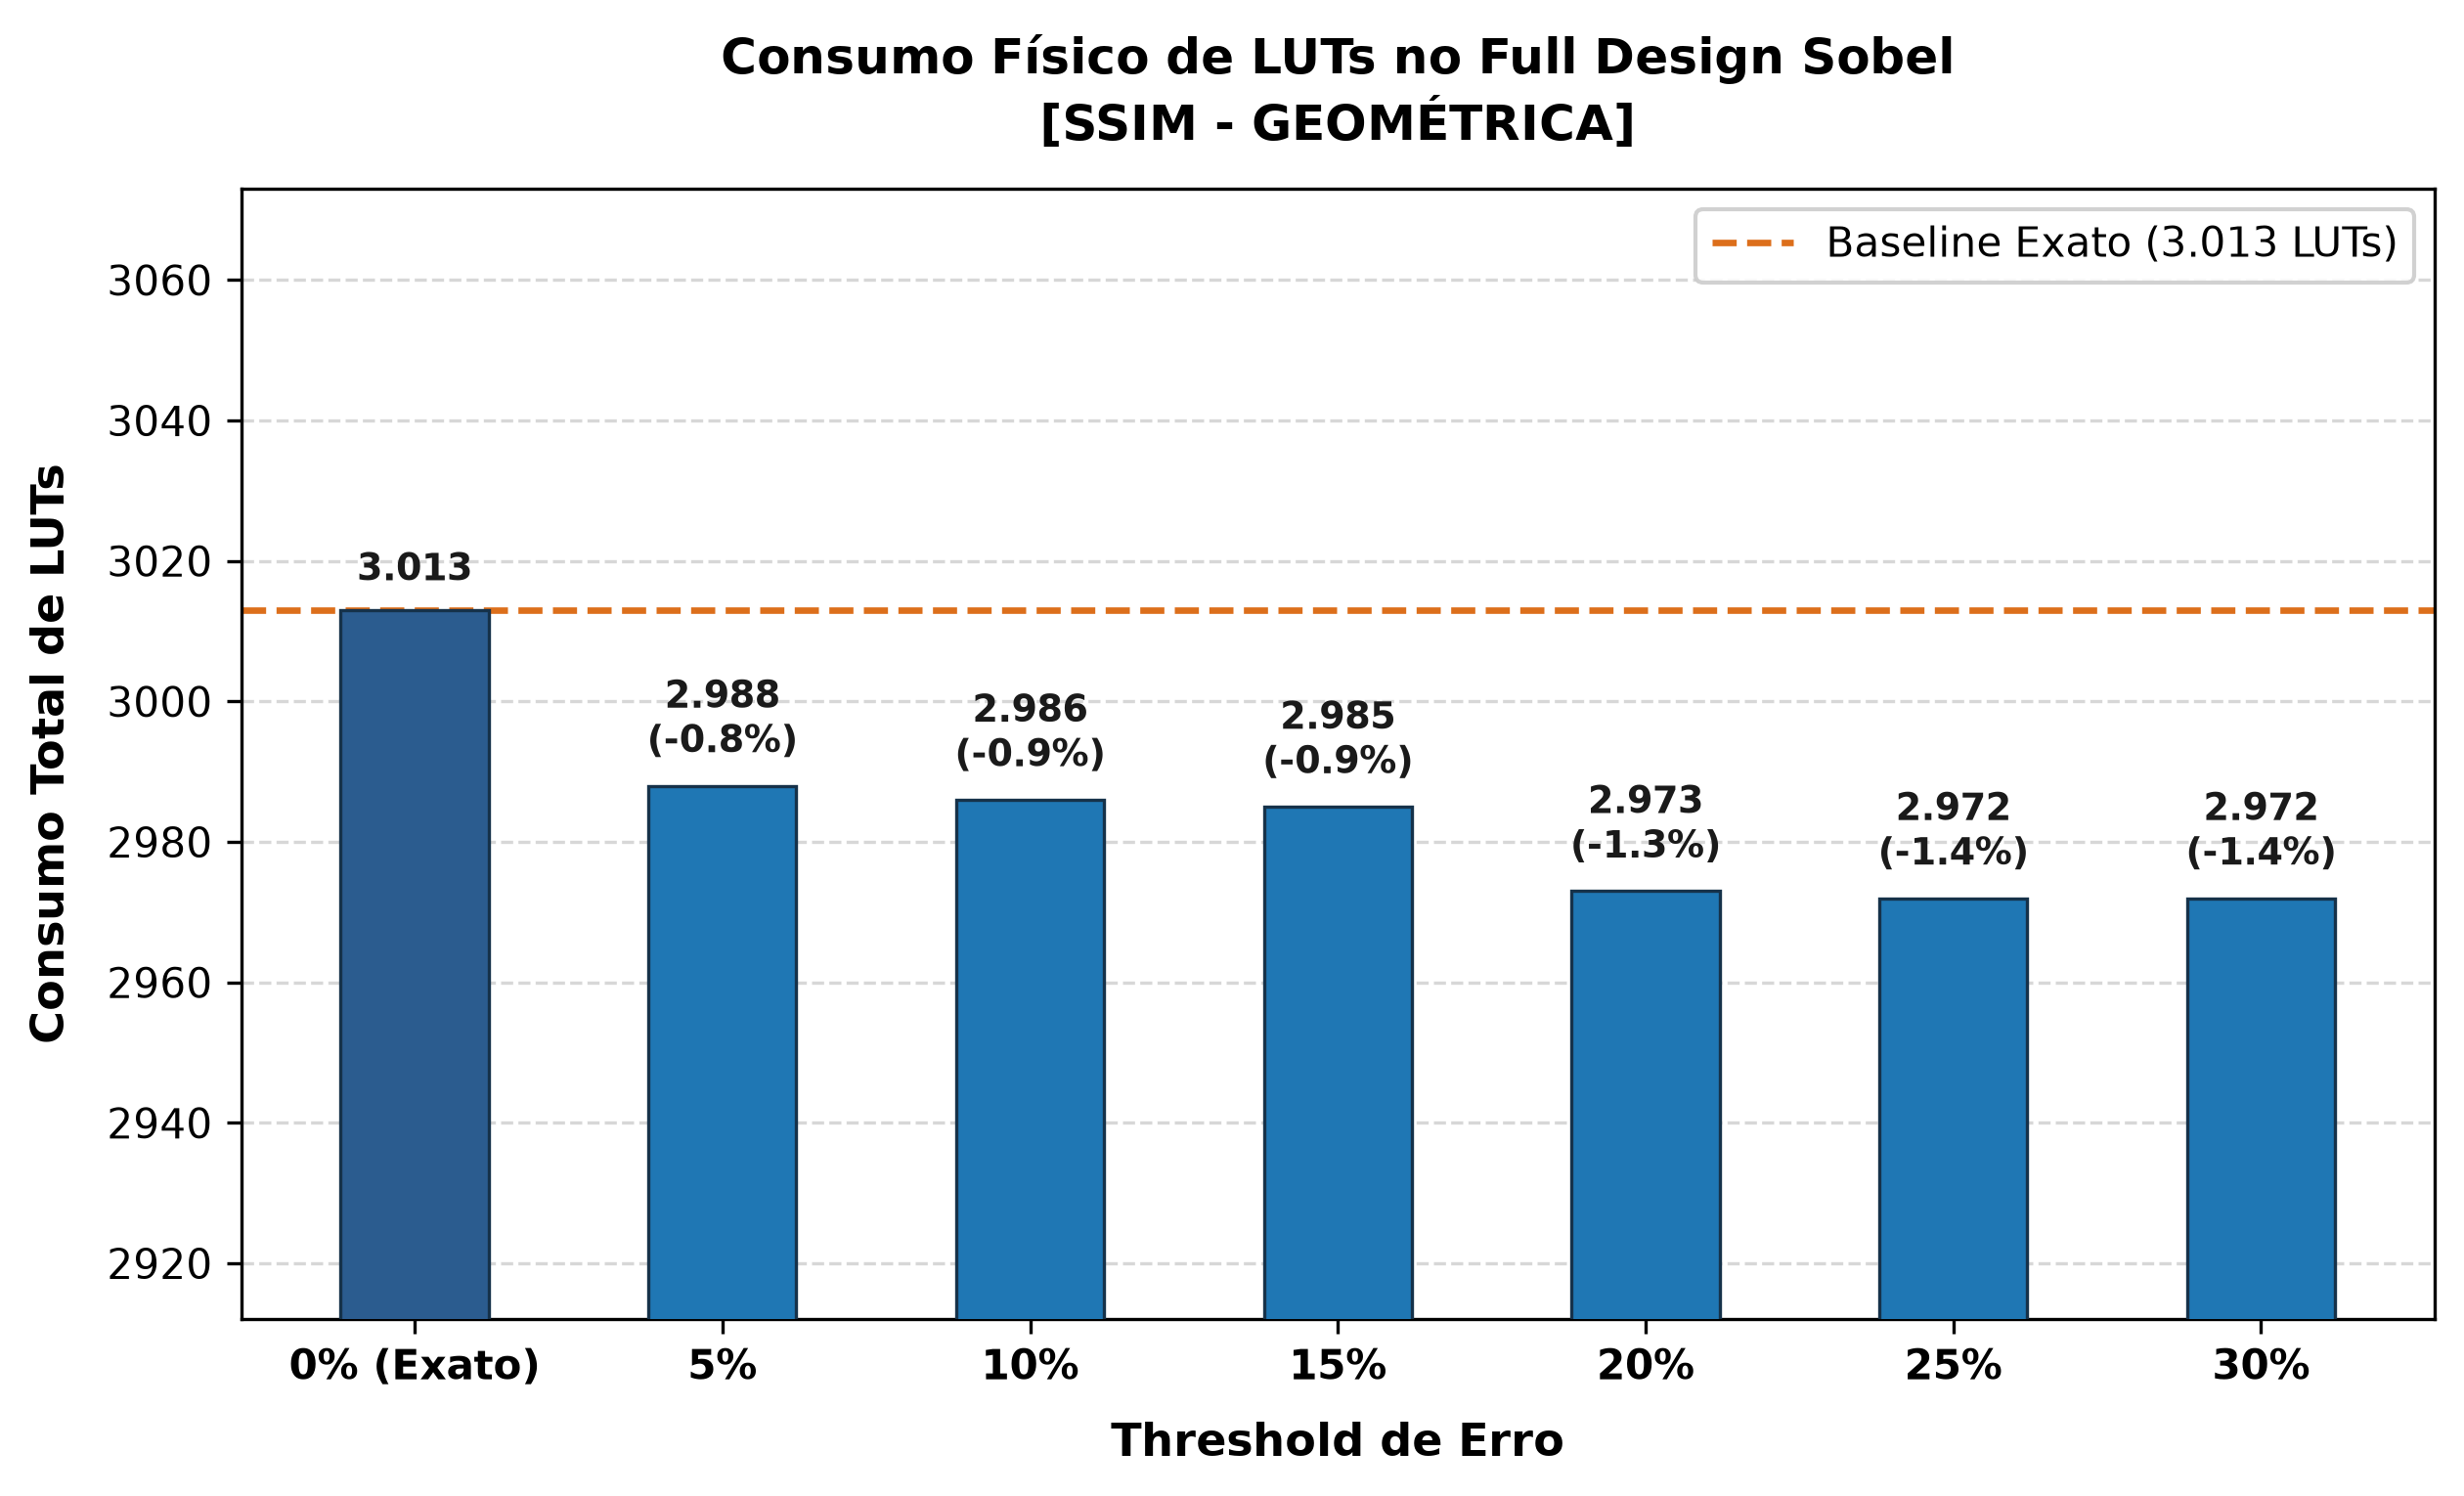

✔ Gráfico 1 salvo: 'grafico_1_luts_full_design_geometrica.png' e 'grafico_1_luts_full_design_geometrica.pdf'


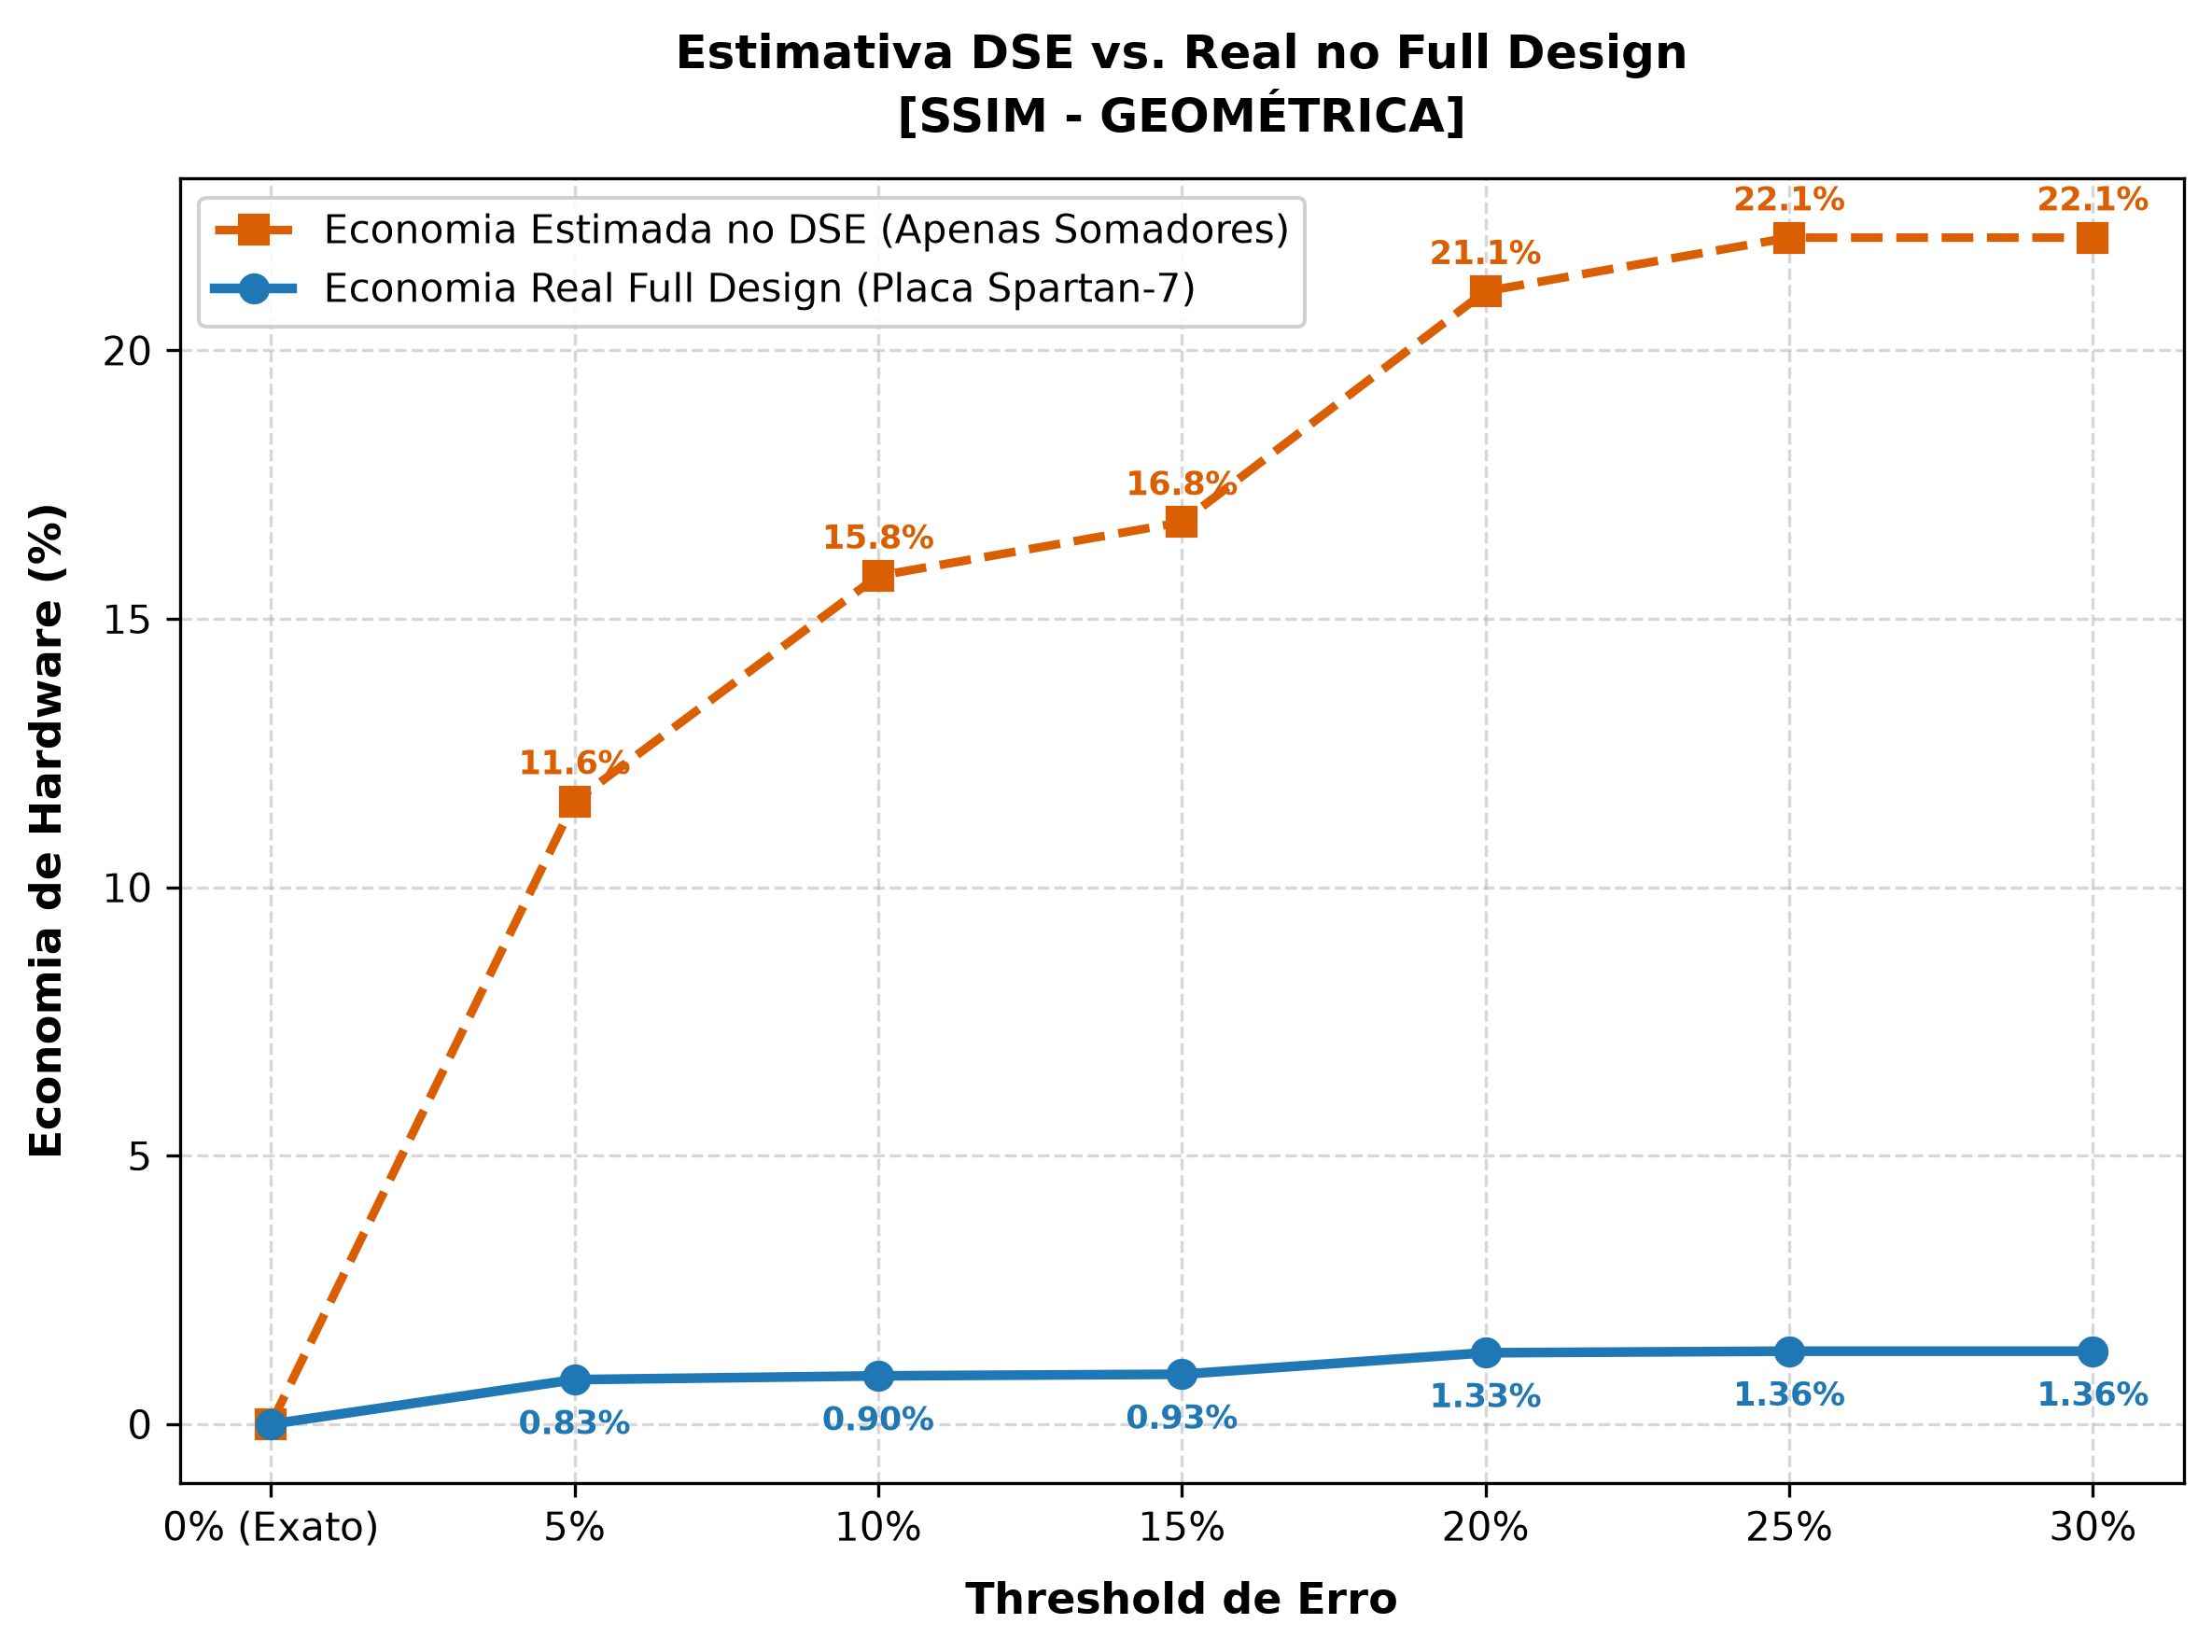

✔ Gráfico 2 salvo: 'grafico_2_economia_full_design_geometrica.png' e 'grafico_2_economia_full_design_geometrica.pdf'


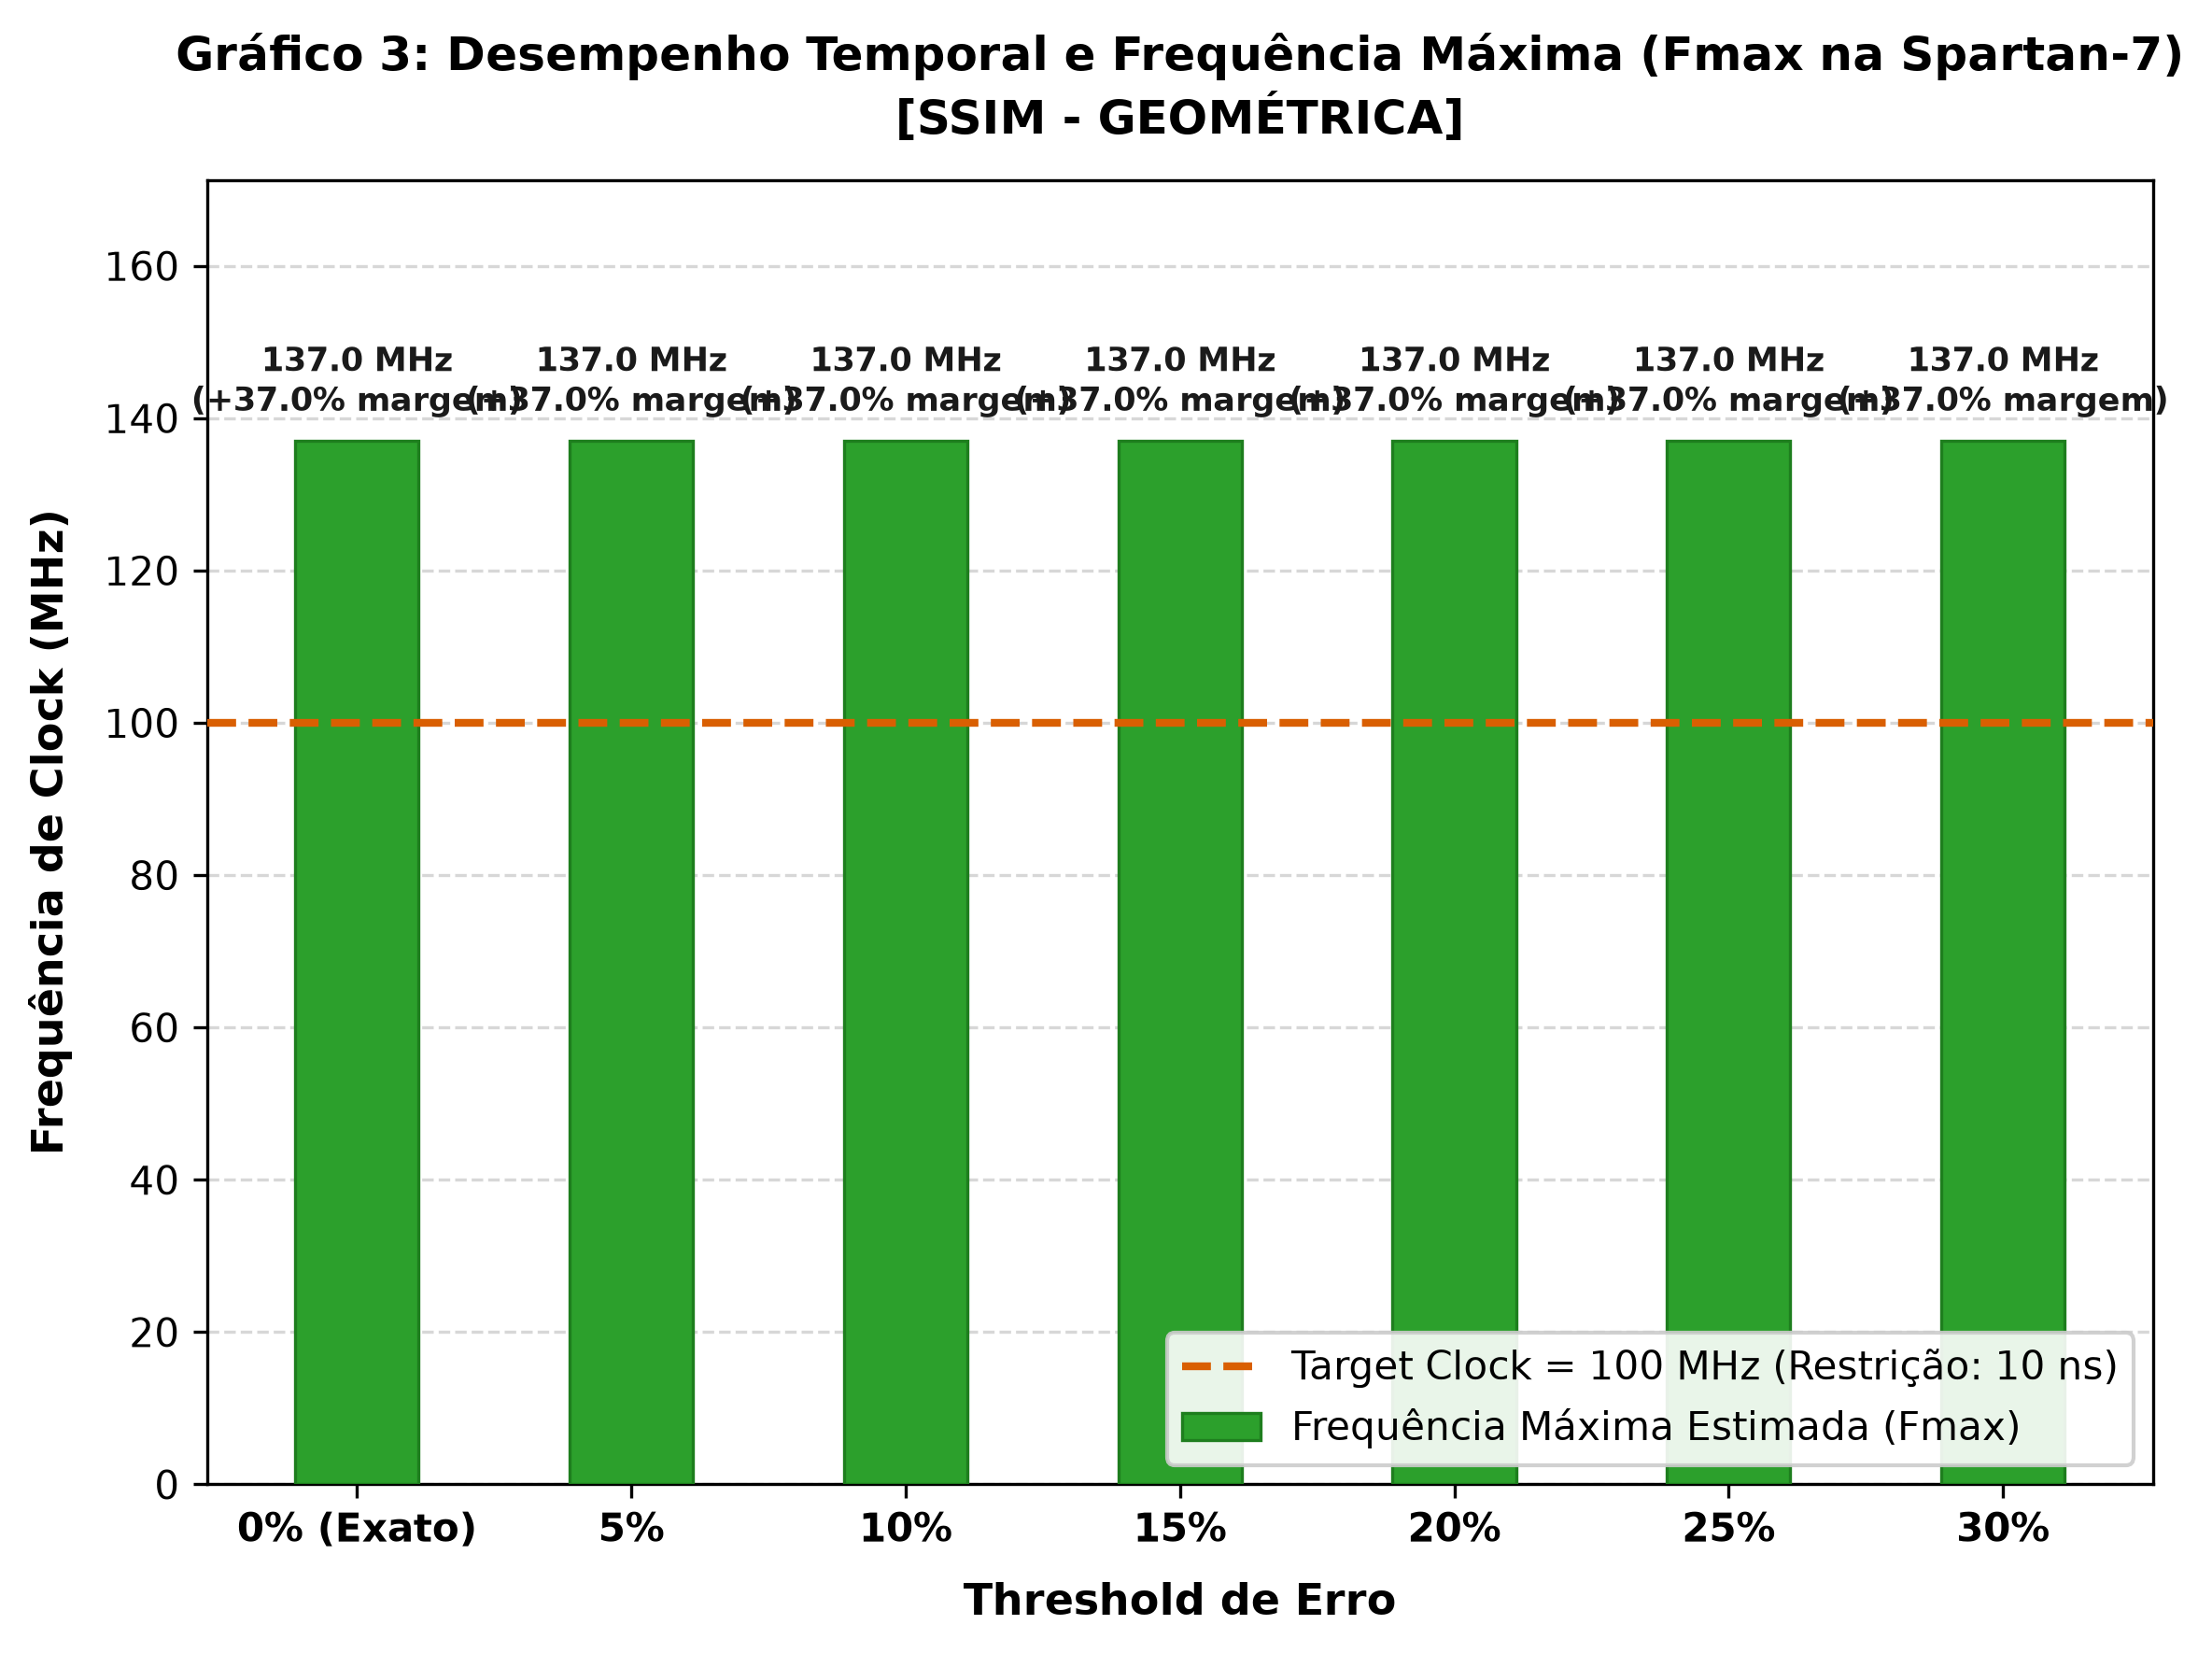

✔ Gráfico 3 salvo: 'grafico_3_timing_full_design_geometrica.png' e 'grafico_3_timing_full_design_geometrica.pdf'


In [ ]:
import os
import re
import xml.etree.ElementTree as ET
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# CONFIGURAÇÃO DE ENTRADA: ESCOLHA DA MÉTRICA E CAMINHOS DE VALIDAÇÃO
# ==============================================================================
# Escolha qual métrica/conjunto de síntese deseja analisar no momento:
# Opções rápidas: "mediana", "geometrico" (ou "geometrica"), "media"
METRICA_ANALISE = "geometrica"

# (Opcional) Sobrescreva manualmente os caminhos se desejar uma pasta customizada.
# Deixe como None para usar o mapeamento automático da métrica escolhida.
PASTA_REPORTS_CUSTOM = None    # Ex: "reports_sintese_mediana" ou None
ARQUIVO_CSV_CUSTOM   = None    # Ex: "resultados_dse_grasp_ssimMediana.csv" ou None

# Mapeamento automático de diretórios de relatórios e arquivos DSE
MAPA_METRICAS = {
    "mediana": {
        "pasta": "reports_sintese_mediana",
        "csv": "resultados_dse_grasp_ssimMediana.csv",
        "label": "SSIM - MEDIANA"
    },
    "geometrico": {
        "pasta": "reports_sintese_geometrico",
        "csv": "resultados_dse_grasp_ssimGeometrica.csv" if os.path.exists("resultados_dse_grasp_ssimGeometrica.csv") else "resultados_dse_grasp_ssimGeometrico.csv",
        "label": "SSIM - GEOMÉTRICA"
    },
    "geometrica": {
        "pasta": "reports_sintese_geometrico",
        "csv": "resultados_dse_grasp_ssimGeometrica.csv" if os.path.exists("resultados_dse_grasp_ssimGeometrica.csv") else "resultados_dse_grasp_ssimGeometrico.csv",
        "label": "SSIM - GEOMÉTRICA"
    },
    "media": {
        "pasta": "reports_sintese_media" if os.path.exists("reports_sintese_media") else "reports_sintese",
        "csv": "resultados_dse_grasp_ssimMedia.csv",
        "label": "SSIM - MÉDIA"
    }
}

chave = METRICA_ANALISE.strip().lower()
cfg = MAPA_METRICAS.get(chave, {
    "pasta": f"reports_sintese_{chave}",
    "csv": f"resultados_dse_grasp_ssim{chave.capitalize()}.csv",
    "label": METRICA_ANALISE
})

PASTA_REPORTS   = PASTA_REPORTS_CUSTOM if PASTA_REPORTS_CUSTOM else cfg["pasta"]
ARQUIVO_CSV_DSE = ARQUIVO_CSV_CUSTOM if ARQUIVO_CSV_CUSTOM else cfg["csv"]
LABEL_METRICA   = cfg.get("label", METRICA_ANALISE)

print("=" * 80)
print(f" VALIDAÇÃO FULL DESIGN VITIS HLS | MÉTRICA: {LABEL_METRICA.upper()}")
print("=" * 80)
print(f"📁 Pasta de Relatórios HLS : '{PASTA_REPORTS}'")
print(f"📄 Arquivo DSE de Entrada  : '{ARQUIVO_CSV_DSE}'")

# ==============================================================================
# FUNÇÕES DE EXTRAÇÃO ROBUSTA DE RELATÓRIOS (XML E RPT)
# ==============================================================================
def _parse_num(elem, as_type=int):
    if elem is None or elem.text is None:
        return None
    val = str(elem.text).strip()
    if val.lower() in ("undef", "?", "n/a", "", "none"):
        return None
    try:
        return as_type(val)
    except Exception:
        return None

def extrair_metricas_xml(xml_path):
    """Extrai recursos e timing do relatório XML do Vitis HLS de forma tolerante."""
    try:
        tree = ET.parse(xml_path)
        root = tree.getroot()
        res = root.find(".//AreaEstimates/Resources")
        luts = _parse_num(res.find("LUT"), int) if res is not None else None
        ffs = _parse_num(res.find("FF"), int) if res is not None else None
        dsps = _parse_num(res.find("DSP"), int) if res is not None else None
        brams = _parse_num(res.find("BRAM_18K"), int) if res is not None else None

        target_clk = _parse_num(root.find(".//TargetClockPeriod"), float)
        est_clk = _parse_num(root.find(".//EstimatedClockPeriod"), float)
        slack = round(target_clk - est_clk, 2) if (target_clk is not None and est_clk is not None) else None
        fmax_mhz = round(1000.0 / est_clk, 2) if (est_clk is not None and est_clk > 0) else None

        lat_elem = root.find(".//PerformanceEstimates/SummaryOfOverallLatency/Worst-caseLatency")
        lat_worst = _parse_num(lat_elem, int)

        return {
            "LUT_full": luts, "FF_full": ffs, "DSP_full": dsps, "BRAM_full": brams,
            "Target_Clock_ns": target_clk, "Est_Clock_ns": est_clk, "Slack_ns": slack,
            "Fmax_MHz": fmax_mhz, "Latency_cycles": lat_worst
        }
    except Exception:
        return None

def extrair_metricas_rpt(rpt_path):
    """Extrai recursos gerais e instância Filter2D do relatório de texto .rpt."""
    try:
        with open(rpt_path, "r", encoding="utf-8") as f:
            texto = f.read()

        match_util = re.search(r"\|Total\s*\|\s*(\d+)?\s*\|\s*(\d+)?\s*\|\s*(\d+)\s*\|\s*(\d+)\s*\|", texto)
        brams = int(match_util.group(1)) if match_util and match_util.group(1) else 0
        dsps = int(match_util.group(2)) if match_util and match_util.group(2) else 0
        ffs = int(match_util.group(3)) if match_util else None
        luts = int(match_util.group(4)) if match_util else None

        match_clk = re.search(r"ap_clk\s*\|\s*([\d\.]+)\s*ns\|\s*([\d\.]+)\s*ns", texto)
        target_clk = float(match_clk.group(1)) if match_clk else None
        est_clk = float(match_clk.group(2)) if match_clk else None
        slack = round(target_clk - est_clk, 2) if (target_clk and est_clk) else None
        fmax_mhz = round(1000.0 / est_clk, 2) if (est_clk and est_clk > 0) else None

        match_filter = re.search(r"\|Filter2D_U0\s*\|\s*Filter2D\s*\|\s*(\d+)\s*\|\s*(\d+)\s*\|\s*(\d+)\s*\|\s*(\d+)\s*\|", texto)
        lut_filter = int(match_filter.group(4)) if match_filter else None

        return {
            "LUT_full": luts, "FF_full": ffs, "DSP_full": dsps, "BRAM_full": brams,
            "LUT_filter": lut_filter,
            "Target_Clock_ns": target_clk, "Est_Clock_ns": est_clk, "Slack_ns": slack,
            "Fmax_MHz": fmax_mhz, "Latency_cycles": None
        }
    except Exception:
        return None

# ==============================================================================
# CARREGAMENTO DOS DADOS DO DSE
# ==============================================================================
df_dse_carregado = None
if os.path.exists(ARQUIVO_CSV_DSE):
    df_dse_carregado = pd.read_csv(ARQUIVO_CSV_DSE)
    print(f"✔ Carregados resultados DSE de '{ARQUIVO_CSV_DSE}' ({len(df_dse_carregado)} configurações).")
elif "df_resultados" in globals() and df_resultados is not None and not df_resultados.empty:
    df_dse_carregado = df_resultados
    print("✔ Utilizando 'df_resultados' presente na memória do notebook.")
else:
    print(f"⚠️ Arquivo DSE '{ARQUIVO_CSV_DSE}' não encontrado localmente.")

# ==============================================================================
# CONSOLIDAÇÃO DOS DADOS DE SÍNTESE (BASELINE 0% + 5% A 30%)
# ==============================================================================
thresholds_analise = [0, 5, 10, 15, 20, 25, 30]
dados_comparacao = []
baseline_luts_real = None
baseline_lut_filter = None
relatorios_encontrados = 0

for th_pct in thresholds_analise:
    tag = f"th_{th_pct:02d}"
    desc = "0% (Exato)" if th_pct == 0 else f"{th_pct}%"

    xml_path = os.path.join(PASTA_REPORTS, f"{tag}_csynth.xml")
    rpt_path = os.path.join(PASTA_REPORTS, f"{tag}_csynth.rpt")

    metricas = None
    if os.path.exists(xml_path):
        metricas = extrair_metricas_xml(xml_path)
    rpt_data = extrair_metricas_rpt(rpt_path) if os.path.exists(rpt_path) else None

    if metricas is None and rpt_data is not None:
        metricas = rpt_data
    elif metricas is not None and rpt_data is not None:
        metricas["LUT_filter"] = rpt_data.get("LUT_filter")

    if metricas is not None and metricas.get("LUT_full") is not None:
        relatorios_encontrados += 1

    # Recupera métricas DSE
    linha_dse = pd.DataFrame()
    if df_dse_carregado is not None and not df_dse_carregado.empty:
        if th_pct == 0:
            linha_dse = df_dse_carregado[(df_dse_carregado["Threshold"] == "0% (Exato)") | (df_dse_carregado["Limite_Erro"] == 0.0)]
        else:
            linha_dse = df_dse_carregado[(df_dse_carregado["Threshold"] == f"{th_pct}%") | (df_dse_carregado["Limite_Erro"].round(2) == round(th_pct / 100.0, 2))]

    if not linha_dse.empty:
        r_dse = linha_dse.iloc[0]
        setup_val = r_dse.get("Setup", "N/A")
        somadores_val = r_dse.get("Somadores", "N/A")
        luts_est = r_dse.get("LUTs", "N/A")
        ssim_val = r_dse.get("SSIM_Teste", "N/A")
        econ_est = r_dse.get("Economia (%)", "N/A")
    else:
        setup_val, somadores_val, luts_est, ssim_val, econ_est = "N/A", "N/A", "N/A", "N/A", "N/A"

    item = {
        "Threshold": desc,
        "Limite_Erro": th_pct / 100.0,
        "SSIM_Teste": ssim_val,
        "LUTs_Est_DSE": luts_est,
        "Econ_Est_%": econ_est,
    }

    if metricas and metricas.get("LUT_full") is not None:
        item["LUTs_Full_Design"] = metricas.get("LUT_full")
        item["FFs_Full_Design"] = metricas.get("FF_full")
        item["DSPs_Full_Design"] = metricas.get("DSP_full")
        item["BRAMs_Full_Design"] = metricas.get("BRAM_full")
        item["LUTs_Kernel_Sobel"] = metricas.get("LUT_filter")
        item["Clock_Est_ns"] = metricas.get("Est_Clock_ns")
        item["Fmax_MHz"] = metricas.get("Fmax_MHz")
        item["Slack_ns"] = metricas.get("Slack_ns")
        item["Latencia_Ciclos"] = metricas.get("Latency_cycles") if metricas.get("Latency_cycles") is not None else "Streaming (Dataflow)"

        if th_pct == 0:
            baseline_luts_real = metricas.get("LUT_full")
            baseline_lut_filter = metricas.get("LUT_filter")
    else:
        item["LUTs_Full_Design"] = "Pendente"
        item["FFs_Full_Design"] = "N/A"
        item["DSPs_Full_Design"] = "N/A"
        item["BRAMs_Full_Design"] = "N/A"
        item["LUTs_Kernel_Sobel"] = "N/A"
        item["Clock_Est_ns"] = "N/A"
        item["Fmax_MHz"] = "N/A"
        item["Slack_ns"] = "N/A"
        item["Latencia_Ciclos"] = "Pendente"

    dados_comparacao.append(item)

# Cálculo de economia real no hardware Spartan-7
for item in dados_comparacao:
    lut_real = item.get("LUTs_Full_Design")
    if baseline_luts_real and isinstance(lut_real, (int, float)):
        item["Econ_Real_%"] = round(100.0 * (1.0 - (lut_real / baseline_luts_real)), 2)
    else:
        item["Econ_Real_%"] = 0.0 if item["Threshold"] == "0% (Exato)" else "Pendente"

    lut_k = item.get("LUTs_Kernel_Sobel")
    if baseline_lut_filter and isinstance(lut_k, (int, float)):
        item["Econ_Kernel_%"] = round(100.0 * (1.0 - (lut_k / baseline_lut_filter)), 2)
    else:
        item["Econ_Kernel_%"] = 0.0 if item["Threshold"] == "0% (Exato)" else "N/A"

df_full_design = pd.DataFrame(dados_comparacao)

# Exibe a tabela consolidada
print(f"\n✔ Relatórios sintetizados encontrados: {relatorios_encontrados} de {len(thresholds_analise)}")
display(df_full_design)

# Salva arquivo CSV específico para esta métrica (preservando outras execuções)
ARQUIVO_CSV_SAIDA = f"resultados_comparacao_full_design_{chave}.csv"
df_full_design.to_csv(ARQUIVO_CSV_SAIDA, index=False)
df_full_design.to_csv("resultados_comparacao_full_design.csv", index=False)
print(f"✔ Tabela consolidada salva com sucesso em '{ARQUIVO_CSV_SAIDA}' (e 'resultados_comparacao_full_design.csv')")

# ==============================================================================
# GERAÇÃO DOS 3 GRÁFICOS SEPARADOS E CENTRALIZADOS
# ==============================================================================
designs_sintetizados = df_full_design[df_full_design["LUTs_Full_Design"].apply(lambda x: isinstance(x, (int, float)))]

if len(designs_sintetizados) > 1:
    x_labels = designs_sintetizados["Threshold"].tolist()
    x_pos = np.arange(len(x_labels))
    luts_plot = designs_sintetizados["LUTs_Full_Design"].tolist()
    econ_est_plot = [float(x) if isinstance(x, (int, float)) else 0.0 for x in designs_sintetizados["Econ_Est_%"].tolist()]
    econ_real_plot = [float(x) if isinstance(x, (int, float)) else 0.0 for x in designs_sintetizados["Econ_Real_%"].tolist()]
    econ_kern_plot = [float(x) if isinstance(x, (int, float)) else 0.0 for x in designs_sintetizados["Econ_Kernel_%"].tolist()]
    fmax_plot = [float(x) if isinstance(x, (int, float)) else 100.0 for x in designs_sintetizados["Fmax_MHz"].tolist()]

    # --------------------------------------------------------------------------
    # GRÁFICO 1: Consumo Físico de LUTs no Spartan-7 (Full Design Sobel)
    # --------------------------------------------------------------------------
    fig1, ax1 = plt.subplots(figsize=(8.5, 5.2), dpi=300)
    cores1 = ["#2b5c8f"] + ["#1f77b4"] * (len(luts_plot) - 1)
    barras1 = ax1.bar(x_pos, luts_plot, color=cores1, width=0.48, edgecolor="#16324a", linewidth=0.8, zorder=3)

    baseline_val = luts_plot[0]
    ax1.axhline(baseline_val, color="#d95f02", linestyle="--", linewidth=1.6, alpha=0.9, zorder=2,
                label=f"Baseline Exato ({baseline_val:,} LUTs)".replace(",", "."))

    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(x_labels, fontweight="bold", fontsize=10)
    ax1.set_xlabel("Threshold de Erro", fontsize=11, fontweight="bold", labelpad=8)
    ax1.set_ylabel("Consumo Total de LUTs", fontsize=11, fontweight="bold", labelpad=8)
    ax1.set_title(f"Consumo Físico de LUTs no Full Design Sobel\n[{LABEL_METRICA}]",
                  fontsize=12, fontweight="bold", pad=12)

    y_min1 = max(0, min(luts_plot) - 60)
    y_max1 = max(luts_plot) + 60
    ax1.set_ylim(y_min1, y_max1)
    ax1.grid(axis="y", linestyle="--", alpha=0.5, zorder=1)

    for i, bar in enumerate(barras1):
        h = bar.get_height()
        diff = baseline_val - h
        txt = f"{h:,}".replace(",", ".")
        if i > 0 and diff > 0:
            pct = (diff / baseline_val) * 100
            txt += f"\n(-{pct:.1f}%)"
        ax1.text(bar.get_x() + bar.get_width() / 2, h + 3, txt,
                 ha="center", va="bottom", fontsize=9, fontweight="bold", color="#1a1a1a")

    ax1.legend(loc="upper right", framealpha=0.9)
    plt.tight_layout()
    fig1_png = f"grafico_1_luts_full_design_{chave}.png"
    fig1_pdf = f"grafico_1_luts_full_design_{chave}.pdf"
    plt.savefig(fig1_png, dpi=300)
    plt.savefig(fig1_pdf)
    plt.show()
    print(f"✔ Gráfico 1 salvo: '{fig1_png}' e '{fig1_pdf}'")

    # --------------------------------------------------------------------------
    # GRÁFICO 2: Economia Estimada (Somadores) vs. Economia Real na Placa (%)
    # --------------------------------------------------------------------------
    fig2, ax2 = plt.subplots(figsize=(8, 6), dpi=300)
    ax2.plot(x_labels, econ_est_plot, marker="s", markersize=7, linewidth=2.2,
             color="#d95f02", linestyle="--", label="Economia Estimada no DSE (Apenas Somadores)")
    ax2.plot(x_labels, econ_real_plot, marker="o", markersize=7, linewidth=2.5,
             color="#1f77b4", linestyle="-", label="Economia Real Full Design (Placa Spartan-7)")


    ax2.set_xlabel("Threshold de Erro", fontsize=11, fontweight="bold", labelpad=8)
    ax2.set_ylabel("Economia de Hardware (%)", fontsize=11, fontweight="bold", labelpad=8)
    ax2.set_title(f"Estimativa DSE vs. Real no Full Design\n[{LABEL_METRICA}]",
                  fontsize=12, fontweight="bold", pad=12)
    ax2.grid(True, linestyle="--", alpha=0.5)

    for i in range(1, len(x_labels)):
        ax2.annotate(f"{econ_est_plot[i]:.1f}%", (x_labels[i], econ_est_plot[i]),
                     textcoords="offset points", xytext=(0, 7),
                     ha="center", fontsize=8.5, fontweight="bold", color="#d95f02")
        ax2.annotate(f"{econ_real_plot[i]:.2f}%", (x_labels[i], econ_real_plot[i]),
                     textcoords="offset points", xytext=(0, -14),
                     ha="center", fontsize=8.5, fontweight="bold", color="#1f77b4")

    ax2.legend(loc="upper left", framealpha=0.9)
    plt.tight_layout()
    fig2_png = f"grafico_2_economia_full_design_{chave}.png"
    fig2_pdf = f"grafico_2_economia_full_design_{chave}.pdf"
    plt.savefig(fig2_png, dpi=300)
    plt.savefig(fig2_pdf)
    plt.show()
    print(f"✔ Gráfico 2 salvo: '{fig2_png}' e '{fig2_pdf}'")


else:
    print(f"\n⚠️ Síntese Vitis HLS pendente ou incompleta na pasta '{PASTA_REPORTS}'.")
    print(f"   Relatórios válidos encontrados: {relatorios_encontrados} de {len(thresholds_analise)}.")
    print("💡 Para executar a síntese no Vitis HLS para esta métrica:")
    print(f"   bash executar_sintese_vitis_{chave}.sh")
    print("💡 Ou para validar a síntese já concluída (ex: mediana):")
    print("   Altere METRICA_ANALISE = 'mediana' no início desta célula.")
